<!-- d2l:prose id=scoring-md-1 fw=all -->

# Scoring Language Models

In that section we classified news headlines by comparing the
log-probabilities of four label words. Apart from one comparison with free
generation, every accuracy of that section came from this one way of reading
an answer, and the section closed by asking what the choice does to a score.
Suppose now that we want to know which of two small models is better at
grade-school science, and take a single question: which gas do plants take in
from the air to make their food? The options are oxygen, carbon dioxide,
nitrogen and water vapor. How do we find out what a model answers?

There are at least three ways (the figure). We can
compare the probabilities that the model assigns to the text of each answer.
We can list the options behind the letters A to D and compare the
probabilities of the four letters. Or we can let the model write, and look
for a letter in what it wrote. All three procedures are reasonable, and
nothing guarantees that they agree.

![One multiple-choice question under three scoring conventions. (a) Cloze: the log-probability of the text of each answer, summed or averaged over its tokens (highlighted). (b) Letter: the log-probability of the letter of each option, after a prompt that lists the options. (c) Generative: the model writes a reply, and a parser extracts the letter that the reply commits to.](../img/mdl-lm-pretrained-scoring-conventions.svg)

A *score* is therefore a convention: a rule, fixed before the experiment,
that turns the outputs of a model into a number. The field had to learn to
write the rule down. In 2023 the maintainers of the Open LLM Leaderboard
[reported](https://huggingface.co/blog/open-llm-leaderboard-mmlu) that three
implementations of one benchmark gave the same models different scores and a
different order. The three programs differed in how they wrote the prompt
and in how they read the answer. An *evaluation harness* is a program that
runs fixed benchmarks on any model under fixed rules, and harnesses such as
lm-evaluation-harness [@Biderman.Schoelkopf.Sutawika.ea.2024] and
standards such as OLMES [@Gu.Tafjord.Kuehl.ea.2025] exist to pin the
rule down.

The later chapters of this part report their comparisons through the scorers
that we build here, so we build them with some care. We start from the
read-out of that section and extend it one step at a time: from
one token to whole answers, from answers to running text, and from
probabilities to text that the model writes, where a parser and sometimes a
program decide what counts as right. At the end five checkpoints meet 500
science questions under eight conventions, and we ask whether the convention
can decide which of two models is ahead.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import collections
import functools
import json
import os
import re
import sys
import textwrap
import time
import unicodedata
import huggingface_hub
import pandas as pd
import transformers

<!-- d2l:prose id=scoring-md-2 fw=all -->

## Datasets and Checkpoints

This part is preparation. A reader in a hurry can skim its three cells and
come back when a name is needed. The section uses three public datasets,
each pinned to a commit of its repository so that the files cannot change
under us (that section). ARC-Challenge
[@Clark.Cowhey.Etzioni.ea.2018] holds multiple-choice questions from
school science exams, selected because two simple baseline methods answered
them wrongly. GSM8K [@Cobbe.Kosaraju.Bavarian.ea.2021] holds word
problems in grade-school arithmetic, and wikitext-2 is a sample of Wikipedia
articles.

The cell also registers two files of fixed inputs, which we describe where
they are used, and the files of *measured results*, four of which this
section reads. Generating a few thousand answers takes the better part of an
hour on a GPU, so a normal run of this notebook reads such results from the
registered files and repeats the cheaper measurements live, as
that section did with its grid of prompts.

In [3]:

# Several of these files share a name: fetch them with d2l.download_keyed
d2l.DATA_HUB['arc-challenge-test'] = (
    'https://huggingface.co/datasets/allenai/ai2_arc/resolve/'
    '210d026faf9955653af8916fad021475a3f00453/ARC-Challenge/'
    'test-00000-of-00001.parquet',
    '029435570dd5b680c95603f2f51a93218fa30cb2')
d2l.DATA_HUB['arc-challenge-train'] = (
    'https://huggingface.co/datasets/allenai/ai2_arc/resolve/'
    '210d026faf9955653af8916fad021475a3f00453/ARC-Challenge/'
    'train-00000-of-00001.parquet',
    '43a863338c7852a03fc5ab79f7c80b88e01a192d')
d2l.DATA_HUB['gsm8k-train'] = (
    'https://huggingface.co/datasets/openai/gsm8k/resolve/'
    '740312add88f781978c0658806c59bc2815b9866/main/'
    'train-00000-of-00001.parquet',
    '2328586d74d5426d030f29ac85a485f58514efbd')
d2l.DATA_HUB['gsm8k-test'] = (
    'https://huggingface.co/datasets/openai/gsm8k/resolve/'
    '740312add88f781978c0658806c59bc2815b9866/main/'
    'test-00000-of-00001.parquet',
    'b0c27c2f1cb845ba83b135c7e2575070b33ca967')
d2l.DATA_HUB['wikitext-2-raw-test'] = (
    'https://huggingface.co/datasets/Salesforce/wikitext/resolve/'
    'b08601e04326c79dfdd32d625aee71d232d685c3/wikitext-2-raw-v1/'
    'test-00000-of-00001.parquet',
    'ab23bd60c20d2e169a8dc2d139ab6e7bf8b74e91')
# Fixed inputs: lm-evaluation-harness's scores on 200 ARC items
# (tools/oneshot/make_lm_eval_arc_fixture.py) and the held-out texts
# (tools/oneshot/make_lm_heldout_texts.py)
d2l.DATA_HUB['lm-eval-reference-arc-v1'] = (
    d2l.LM_DATA_URL + 'lm-eval-reference-arc-v1.json',
    'c0bdeb8593b0ba75406025d06e8cbea9016a2c71')
d2l.DATA_HUB['lm-heldout-texts-v1'] = (
    d2l.LM_DATA_URL + 'lm-heldout-texts-v1.json',
    '11b0ed4fead96910fba1078b2d9f5ee5b6a59b69')
# This section's measured results, written by a run with D2L_RERUN (the
# keys in use are in ARTIFACTS below). The next section reads
# lm-gsm8k-samples-v2 and lm-arc-scores-v3; the API section reads the
# problem ids of lm-gsm8k-samples-v1
d2l.DATA_HUB['lm-gsm8k-samples-v1'] = (
    d2l.LM_DATA_URL + 'lm-gsm8k-samples-v1.jsonl',
    '11b561b6fb07d19016f5a00b4a5dcf35d3dbbb07')
d2l.DATA_HUB['lm-gsm8k-samples-v2'] = (
    d2l.LM_DATA_URL + 'lm-gsm8k-samples-v2.jsonl',
    'e02bde69f9fca1f0af49d1170088d87a304ceb0f')
d2l.DATA_HUB['lm-bpb-v3'] = (
    d2l.LM_DATA_URL + 'lm-bpb-v3.csv',
    '1afa5c853c605511c3c5d8f41ee4607ee7bfd12b')
d2l.DATA_HUB['lm-arc-generations-v5'] = (
    d2l.LM_DATA_URL + 'lm-arc-generations-v5.jsonl',
    'c4f2733f91d489a0b89101531a037f12e77a03c8')
d2l.DATA_HUB['lm-arc-scores-v3'] = (
    d2l.LM_DATA_URL + 'lm-arc-scores-v3.parquet',
    '7f3e186697deceed231f826da256c2fce646eef1')

<!-- d2l:prose id=scoring-md-3 fw=all -->

We score five checkpoints. Recall from that section that a
*base* model was trained only to continue text, and that a *post-trained*
one was trained further by its authors to follow instructions and to hold a
conversation. Qwen3-0.6B and Qwen3.5-0.8B are the two post-trained models
that we want to compare, and we name them as our pair here, before any score
exists. Their base twins join for the measurements on running text and for a
comparison with an independent implementation, and Qwen3-1.7B joins as a
larger model for the experiments on reasoning.

The dictionary `ARTIFACTS` names the four measured results, and `result`
returns the registered file of each unless the environment variable
`D2L_RERUN` asks this run to regenerate it. Several checks below use fp32 as
their reference, so the two `allow_tf32` lines switch off tf32
(that section), which would compute matrix products with a 10-bit
mantissa.

In [4]:
BASES = ['Qwen/Qwen3-0.6B-Base', 'Qwen/Qwen3.5-0.8B-Base']
PAIR = ['Qwen/Qwen3-0.6B', 'Qwen/Qwen3.5-0.8B']  # the pre-declared pair
MODELS = [BASES[0], PAIR[0], BASES[1], PAIR[1], 'Qwen/Qwen3-1.7B']
GPU = torch.cuda.is_available()
# A job given a GPU (CUDA_VISIBLE_DEVICES set) must not fall back to the CPU
assert GPU or not os.environ.get('CUDA_VISIBLE_DEVICES'), (
    'a GPU is assigned, but PyTorch sees none')
ARTIFACTS = {  # measured result: (registered key, file a regeneration writes)
    'bpb': ('lm-bpb-v3', 'lm-bpb.csv'),
    'gsm8k-samples': ('lm-gsm8k-samples-v2', 'lm-gsm8k-samples.jsonl'),
    'arc-generations': ('lm-arc-generations-v5', 'lm-arc-generations.jsonl'),
    'arc-scores': ('lm-arc-scores-v3', 'lm-arc-scores.parquet')}
RERUN = d2l.lm_rerun(ARTIFACTS)  # D2L_RERUN=1: all four; unset: none
assert GPU or not RERUN, 'regenerating the artifacts needs a GPU'

def result(name):
    """The file of a measured result: the one this run regenerated if
    D2L_RERUN names it, else the registered one."""
    key, file = ARTIFACTS[name]
    return d2l.lm_artifact(key, file if name in RERUN else None)

torch.backends.cuda.matmul.allow_tf32 = False  # fp32 means IEEE fp32
torch.backends.cudnn.allow_tf32 = False
ieee_fp32 = lambda: not (torch.backends.cuda.matmul.allow_tf32 or
                         torch.backends.cudnn.allow_tf32)
transformers.logging.set_verbosity_error()  # no notices or progress bars
transformers.logging.disable_progress_bar()
huggingface_hub.utils.disable_progress_bars()
print(f'GPU={GPU}, RERUN={",".join(sorted(RERUN)) or False}')

GPU=True, RERUN=False


<!-- d2l:prose id=scoring-md-4 fw=all -->

From the 1,172 test items of ARC-Challenge we take 500 by a seeded
permutation, and 100 of the 1,319 test problems of GSM8K in the same way.
The rule is prefix-stable: a subset of 100 items is the first 100 of our 500,
so a cheaper experiment on fewer items stays comparable with the full one.
The cell also takes five solved items from the training split to serve as
demonstrations. Their correct letters are A, B, C, D and A, spread on
purpose so that the demonstrations do not teach a model a favorite letter.
Whether that works is checked at the end of the section.

In [5]:
def arc_items(df):
    """(id, question, options, gold index) per row; the index also reads
    the items labelled 1 to 4 instead of A to D."""
    return [(r.id, r.question, list(r.choices['text']),
             list(r.choices['label']).index(r.answerKey))
            for r in df.itertuples()]

def subset(n_total, n, seed=0):  # prefix-stable: subset(N, m) starts
    return np.random.default_rng(seed).permutation(n_total)[:n]  # (N, n)

arc_test, arc_train = (arc_items(pd.read_parquet(d2l.download_keyed(
    f'arc-challenge-{split}'))) for split in ('test', 'train'))
ARC = [arc_test[i] for i in subset(len(arc_test), 500)]
ARC_IDS, GOLD = [it[0] for it in ARC], np.array([it[3] for it in ARC])
SHOTS, shot_ids = [], []  # in train order, gold letters A, B, C, D, A
for letter in 'ABCDA':
    it = next(it for it in arc_train if len(it[2]) == 4 and
              'ABCD'[it[3]] == letter and it[0] not in shot_ids)
    shot_ids.append(it[0])
    SHOTS.append(it[1:])
gsm_train = pd.read_parquet(d2l.download_keyed('gsm8k-train'))
gsm_test = pd.read_parquet(d2l.download_keyed('gsm8k-test'))
GSM_IDS = subset(len(gsm_test), 100)  # row indices of the test file
print(f'ARC-Challenge: {len(ARC)} of {len(arc_test):,} test items; options '
      f'per item {dict(collections.Counter(len(it[2]) for it in ARC))}')
print('demonstrations (id, gold letter):')
for i, shot in zip(shot_ids, SHOTS):
    print(f'    {i} ({"ABCD"[shot[2]]})')
print(f'GSM8K: {len(GSM_IDS)} of {len(gsm_test):,} test problems')

ARC-Challenge: 500 of 1,172 test items; options per item {4: 494, 5: 3, 3: 3}
demonstrations (id, gold letter):
    Mercury_SC_415702 (A)
    MCAS_2009_5_6516 (B)
    MEA_2016_8_14 (C)
    Mercury_7041615 (D)
    MDSA_2008_5_30 (A)
GSM8K: 100 of 1,319 test problems


<!-- d2l:prose id=scoring-md-5 fw=all -->

Almost all items have four options, three have five and three have three, so
guessing is right about one time in four. The outputs of this section call
the correct option of an item its *gold* option, as the field does.

## Likelihood Scores

A language model assigns a probability to any text that might follow a
prompt. To turn that into the answer to a multiple-choice item we must decide
what the prompt is, which texts we compare, and how we compare them. Let us
start with the first two decisions, which are a matter of layout.

### Cloze and Letter Formats

`d2l.format_mc` writes an item as a prompt and a list of *choices*, the texts
whose probabilities will be compared. It has two main formats. In the
*cloze* format the prompt is the question followed by `Answer:`, and the
choices are the texts of the options. The name is the one OLMES uses, after
the cloze test, in which a reader fills a blank in a text. In the *letter*
format, which OLMES calls the multiple-choice formulation, the prompt lists
the options behind the letters A, B, C and so on, and the choices are the
letters. (A third format, `mmlu`, is the letter format without the word
`Question:`, as one widely used benchmark writes its items.) Solved items
passed as `shots` are written in the same format and placed in front as
demonstrations.

In [6]:

def format_mc(question, options, fmt='cloze', *, shots=()):
    """A multiple-choice item as (prompt, choices). 'cloze': the prompt
    'Question: {question}\\nAnswer:' and each option after a space;
    'letter': 'Question: {question}', a line 'A. {option}' per option and
    'Answer:', with the letters ' A', ' B', ... as choices (OLMES's
    multiple-choice formulation); 'mmlu': the same without 'Question: ',
    as the MMLU paper and lm-evaluation-harness's mmlu tasks write it. Each
    shot, a tuple (question, options, answer_index), is rendered the same
    way with its answer and put before the item, separated by a blank line.
    Callers that want a header (such as MMLU's subject line) prepend it
    themselves."""
    if fmt not in ('cloze', 'letter', 'mmlu'):
        raise ValueError(f'unknown fmt: {fmt!r}')

    def render(q, opts):
        opts = [str(o) for o in opts]  # also numpy arrays, pandas Series
        if not opts:
            raise ValueError(f'no options for {q!r}')
        if fmt == 'cloze':
            return f'Question: {q}\nAnswer:', [' ' + o for o in opts]
        if len(opts) > 26:
            raise ValueError(f'{len(opts)} options, but 26 letters')
        letters = [chr(ord('A') + i) for i in range(len(opts))]
        lines = [q if fmt == 'mmlu' else f'Question: {q}'] + [
            f'{a}. {o}' for a, o in zip(letters, opts)]
        return '\n'.join(lines + ['Answer:']), [' ' + a for a in letters]
    blocks = []
    for q, opts, a in shots:
        prompt, choices = render(q, opts)
        if not 0 <= a < len(choices):
            raise ValueError(f'answer index {a} for {len(choices)} options')
        blocks.append(prompt + choices[a])
    prompt, choices = render(question, options)
    return '\n\n'.join(blocks + [prompt]), choices

<!-- d2l:prose id=scoring-md-6 fw=all -->

Here is the question about plants in both formats, with the tokens that each
choice adds to its prompt under the tokenizer of Qwen3-0.6B-Base.

In [7]:
TOK = {m: transformers.AutoTokenizer.from_pretrained(
    m, revision=d2l.HF_REVISIONS[m]) for m in BASES}
tok = TOK[BASES[0]]
question = 'Which gas do plants take in from the air to make their food?'
options = ['oxygen', 'carbon dioxide', 'nitrogen', 'water vapor']
for fmt in ('cloze', 'letter'):
    prompt, choices = d2l.format_mc(question, options, fmt)
    n = len(tok(prompt, add_special_tokens=False).input_ids)
    print(prompt)
    for c in choices:  # the continuation: tokens beyond the prompt's
        cont = tok(prompt + c, add_special_tokens=False).input_ids[n:]
        print(f'    {c!r:17} ids {cont}, pieces '
              f'{[tok.decode(i) for i in cont]}')

Question: Which gas do plants take in from the air to make their food?
Answer:
    ' oxygen'         ids [23552], pieces [' oxygen']
    ' carbon dioxide' ids [12499, 39489], pieces [' carbon', ' dioxide']
    ' nitrogen'       ids [46403], pieces [' nitrogen']
    ' water vapor'    ids [3015, 37652], pieces [' water', ' vapor']
Question: Which gas do plants take in from the air to make their food?
A. oxygen
B. carbon dioxide
C. nitrogen
D. water vapor
Answer:
    ' A'              ids [362], pieces [' A']
    ' B'              ids [425], pieces [' B']
    ' C'              ids [356], pieces [' C']
    ' D'              ids [422], pieces [' D']


<!-- d2l:prose id=scoring-md-7 fw=all -->

In the cloze format the choices are words or pairs of words: `' oxygen'` is
one token and `' carbon dioxide'` two. In the letter format every choice is a
single token, a letter with its leading space. The two formats also ask for
different things. The cloze format asks how probable an answer is as a
continuation of the question, and the model never sees what that answer
competes with. The letter format asks the model to read four options, choose
one and name its letter, and naming the letter is a second skill next to
knowing the answer. @Robinson.Rytting.Wingate.2023 found that skill
very unevenly distributed among the models of 2022, some of which could
hardly bind a letter to its option. Whether the small models of today can is
something we will measure.

What does a model answer to the question about plants? We cannot say yet.
First we build the scorer and make sure that it can be trusted. The plants
get their answer as soon as the rules for comparing choices are in place,
and 500 exam questions get theirs in that section.

### Continuations and the Token Boundary

The score of a choice is the log-probability of its tokens given the prompt.
If the choice $c$ adds the tokens $c_1, \ldots, c_m$ to the prompt $x$, the
chain rule gives

$$
\ell(c \mid x) = \log P(c \mid x) = \sum_{t=1}^{m} \log p(c_t \mid x, c_{<t}),
$$

and all $m$ terms come out of one forward pass over prompt and choice
together, because the model predicts every next token of its input at once.
For `' carbon dioxide'` the sum has two terms: the log-probability of
`' carbon'` after the prompt, and that of `' dioxide'` after the prompt and
`' carbon'`. This is the read-out of that section with
more than one token per label, and without its renormalization over the
labels.

The sum takes for granted that we can tell which tokens belong to the choice.
A tokenizer does not promise this. The tokens of prompt and choice together
need not begin with the tokens of the prompt: had we ended the prompt with a
space, that space would have been absorbed into the first token of the
answer, as that section found for label words. The scorer
follows the rule of lm-evaluation-harness. Whitespace at the end of the
prompt moves to the front of the choice, the prompt and the whole text are
tokenized separately, and the *continuation* is what the whole has beyond the
tokens of the prompt.

The rule can still fail. A *merge* occurs when the last token of the prompt
changes once the choice is attached, and then the scored tokens no longer
spell the text we meant. The next cell writes the 500 items in the four
formats that we will score and counts the merges under both tokenizers. (The
fourth format, `uncond`, puts each option after the bare prompt `Answer:`. A
normalization below needs it.)

In [8]:
FORMATS = {  # (prompt, choices) of the 500 items in each scored format
    'cloze': [d2l.format_mc(q, o) for _, q, o, _ in ARC],
    'uncond': [('Answer:', d2l.format_mc(q, o)[1]) for _, q, o, _ in ARC],
    'letter0': [d2l.format_mc(q, o, 'letter') for _, q, o, _ in ARC],
    'letter5': [d2l.format_mc(q, o, 'letter', shots=SHOTS)
                for _, q, o, _ in ARC]}
merges = collections.defaultdict(dict)
for m, t in TOK.items():
    for fmt, items in FORMATS.items():
        heads = t([p for p, cs in items for _ in cs],
                  add_special_tokens=False).input_ids
        whole = t([p + c for p, cs in items for c in cs],
                  add_special_tokens=False).input_ids
        merges[fmt][m] = sum(w[:len(h)] != h for h, w in zip(heads, whole))
    assert all(len(t(' ' + a, add_special_tokens=False).input_ids) == 1
               for a in 'ABCDEFGHIJ')  # ' A' to ' J' are single tokens
print(f'prompt-choice pairs per format: '
      f'{sum(len(cs) for _, cs in FORMATS["cloze"]):,}; merges:')
print(pd.DataFrame(merges))

prompt-choice pairs per format: 2,000; merges:
                        cloze  uncond  letter0  letter5
Qwen/Qwen3-0.6B-Base        0       0        0        0
Qwen/Qwen3.5-0.8B-Base      0       0        0        0


<!-- d2l:prose id=scoring-md-8 fw=all -->

None of the 2,000 pairs of prompt and choice merges, in any format, under
either tokenizer. Every score below is therefore the log-probability of the
text it claims to score. The assertion in the cell confirms that the letters
from `' A'` to `' J'` are single tokens. The boundary rule is a detail that
can be forgotten once it has been checked, and it has to be checked again for
every new tokenizer and every new prompt format.

One forward pass yields more than one score. A sum of log-probabilities
favors short answers, as the next subsection shows, and the usual remedy
divides it by a length. For every choice `ScoreComponents` therefore keeps
the summed log-probability `ll` and three lengths by which one might divide,
in tokens, characters and bytes. Every rule for comparing choices in this
section is a function of these four numbers, and one rule needs a second
pass besides.

In [9]:

ScoreComponents = collections.namedtuple(  # each (N, C_max), padded with
    'ScoreComponents', 'll n_tokens n_chars n_bytes')  # -inf (ll) and 0

<!-- d2l:prose id=scoring-md-9 fw=all -->

`d2l.score_choices` computes them. Three of its steps carry the idea. It pads
the prompts on the left, so that every row of a batch ends with its
continuation. It keeps only the hidden states at the positions that predict a
continuation token: the output layer of these models has between 150,000 and
250,000 rows, and logits for every position of every prompt would fill the
GPU with numbers that nobody reads. And it applies the output layer and the
log-softmax to those few states in fp32, as `d2l.label_logprobs` did, because
bf16 logits lie on a coarse grid on which close choices tie
(that section). The rest is batching, with the longest
inputs first.

In [10]:

def score_choices(model, tokenizer, prompts, choices, norm='token', *,
                  batch_size=8, return_components=False):
    """Log-likelihood scores (N, C_max) of each choice after its prompt,
    -inf in padded columns; the prediction is argmax(-1). choices holds N
    lists (ragged) or one list shared by all prompts. norm divides the
    summed log-probability ll: 'sum' by 1, 'token' by the continuation's
    tokens, 'char' and 'byte' by the length and UTF-8 length of the choice
    without one leading whitespace character (lm-evaluation-harness's
    acc_norm and acc_bytes). The continuation is the suffix of
    encode(prompt + choice) beyond encode(prompt), trailing prompt
    whitespace moved to the choice, no BOS (see _lm_continuations). With
    return_components=True, returns ScoreComponents, from which every norm
    follows. The scored positions are projected by the output layer in
    fp32 (as label_logprobs does) and log-softmaxed in fp32. In bf16 an
    item's score depends on which items share its batch, so a different
    call over the same items (another batch size or item set) agrees only
    up to that batch drift, not bit for bit."""
    if norm not in ('sum', 'token', 'char', 'byte'):
        raise ValueError(f'unknown norm: {norm!r}')
    rows, inputs, conts, texts, shape = d2l._lm_continuations(
        tokenizer, prompts, choices, d2l._lm_max_len(model))
    head = d2l._label_output_layer(model)  # a plain linear layer, or None
    if head is not None:  # its weights in fp32, once per call
        W = head.weight.float()
        bias = None if head.bias is None else head.bias.float()
    pad = getattr(tokenizer, 'pad_token_id', None) or 0
    device = next(model.parameters()).device
    order = sorted(range(len(rows)), key=lambda r: (-len(inputs[r]), r))
    ll = torch.empty(len(rows), dtype=torch.float64)
    for s in range(0, len(order), batch_size):  # longest inputs first
        b = order[s:s + batch_size]
        x, m = [inputs[r] for r in b], [len(conts[r]) for r in b]
        y = torch.tensor([t for r in b for t in conts[r]], device=device)
        with torch.inference_mode():
            if head is None:  # a d2l GPT, or a soft-capped output layer
                H = d2l._lm_cont_logits(model, x, m, pad)
            else:  # left padding: every row ends with its continuation
                T = max(map(len, x))
                X = torch.tensor([[pad] * (T - len(r)) + r for r in x],
                                 device=device)
                mask = torch.tensor([[0] * (T - len(r)) + [1] * len(r)
                                     for r in x], device=device)
                pos = (mask.cumsum(-1) - 1).masked_fill(mask == 0, 1)
                H = d2l._lm_unwrap(model).get_decoder()(
                    input_ids=X, attention_mask=mask, position_ids=pos,
                    use_cache=False).last_hidden_state
                H = torch.cat([H[k, T - mk:] for k, mk in enumerate(m)])
            lp = []  # fp32, at most 1,024 scored positions at a time
            for i in range(0, len(y), 1024):
                z = H[i:i + 1024].float()
                z = z if head is None else F.linear(z, W, bias)
                lp.append(z.log_softmax(-1).gather(
                    -1, y[i:i + 1024, None])[:, 0])
            lp = torch.cat(lp).double()
        ll[b] = torch.stack([v.sum() for v in lp.split(m)]).cpu()
    comps = d2l._lm_components(rows, ll, conts, texts, shape)
    if return_components:
        return comps
    return comps.ll / {'sum': 1, 'token': comps.n_tokens,
                       'char': comps.n_chars, 'byte': comps.n_bytes}[norm]

<!-- d2l:prose id=scoring-md-10 fw=all -->

The later chapters of this part import this function, so we check it against
three independent references. `hand_loop` evaluates the equation in
the plainest way, from the log-softmax of the full sequence, one choice at a
time. Scoring a batch of eight must give what scoring one item at a time
gives. And in the letter format, our scores renormalized over the four
letters must reproduce `d2l.label_logprobs` with the label words A to D.

In [11]:
def hand_loop(model, tok, prompt, choice):
    """log P(choice | prompt) from the log-softmax of the whole sequence."""
    n = len(tok(prompt, add_special_tokens=False).input_ids)
    ids = tok(prompt + choice, add_special_tokens=False).input_ids
    with torch.inference_mode():
        z = model(torch.tensor([ids], device=model.device)).logits[0]
    lp = z.float().log_softmax(-1)
    return sum(lp[t - 1, ids[t]].item() for t in range(n, len(ids)))

def scorer_errors(model, tok, items, letter_prompts):
    """Largest differences between score_choices and three references."""
    prompts, choices = zip(*items)
    hand = torch.tensor([[hand_loop(model, tok, p, c) for c in cs]
                         for p, cs in items])
    total = d2l.score_choices(model, tok, prompts, choices, 'sum',
                              batch_size=1)  # as the loop: no batch drift
    one = d2l.score_choices(model, tok, prompts, choices, batch_size=1)
    eight = d2l.score_choices(model, tok, prompts, choices, batch_size=8)
    letters = d2l.score_choices(model, tok, letter_prompts,  # one prompt
                                [' A', ' B', ' C', ' D'], 'sum',  # at a
                                batch_size=1)  # time: no batch drift
    labels = d2l.label_logprobs(model, tok, letter_prompts, list('ABCD'),
                                batch_size=1)
    return [('sum vs hand loop', (total - hand).abs().max().item(), 1e-4),
            ('batch 8 vs 1', (eight - one).abs().max().item(), 1e-4),
            ('letters vs label_logprobs',
             (letters.log_softmax(-1) - labels).abs().max().item(), 1e-5)]

<!-- d2l:prose id=scoring-md-11 fw=all -->

We run the checks in fp32 on the first eight four-option items for both base
checkpoints, and the letter check once more in bf16. Qwen3.5 is the delicate
case for left padding. It is a hybrid whose recurrent layers carry a state
from token to token (that section), and padding in front of a
prompt must not leak into that state.

In [12]:
assert ieee_fp32()  # the fp32 checks assume IEEE fp32 matrix products
first8 = [i for i, it in enumerate(ARC) if len(it[2]) == 4][:8]
items = [FORMATS['cloze'][i] for i in first8]
letter_prompts = [FORMATS['letter0'][i][0] for i in first8]
model, tok = d2l.load_hf(BASES[1], dtype=torch.float32)
rows = [(BASES[1], *r)
        for r in scorer_errors(model, tok, items, letter_prompts)]
del model
d2l.lm_free()
base32, tok32 = d2l.load_hf(BASES[0], dtype=torch.float32)  # kept below
rows += [(BASES[0], *r)
         for r in scorer_errors(base32, tok32, items, letter_prompts)]
if GPU:  # bf16: both read one hidden state through an fp32 output layer
    base16, _ = d2l.load_hf(BASES[0])  # kept below
    letters = d2l.score_choices(base16, tok32, letter_prompts,
                                [' A', ' B', ' C', ' D'], 'sum', batch_size=1)
    labels = d2l.label_logprobs(base16, tok32, letter_prompts, list('ABCD'),
                                batch_size=1)
    rows.append((BASES[0], 'letters vs label_logprobs, bf16',
                 (letters.log_softmax(-1) - labels).abs().max().item(), 1e-5))
print(pd.DataFrame(rows, columns=['model', 'check', 'max error', 'tolerance'])
      .to_string(index=False, float_format='%.1e'))
assert all(err < tol for *_, err, tol in rows)

Qwen/Qwen3.5-0.8B-Base@dc7cdfe2ee41: Qwen3_5ForCausalLM, stop tokens [248044]
0 missing keys; unexpected keys: none
kernels: attention sdpa, delta rule PyTorch, short convolution PyTorch


Qwen/Qwen3-0.6B-Base@da87bfb608c1: Qwen3ForCausalLM, stop tokens [151643]
0 missing keys; unexpected keys: none
kernels: attention sdpa


Qwen/Qwen3-0.6B-Base@da87bfb608c1: Qwen3ForCausalLM, stop tokens [151643]
0 missing keys; unexpected keys: none
kernels: attention sdpa


                 model                           check  max error  tolerance
Qwen/Qwen3.5-0.8B-Base                sum vs hand loop    3.8e-05    1.0e-04
Qwen/Qwen3.5-0.8B-Base                    batch 8 vs 1    2.4e-05    1.0e-04
Qwen/Qwen3.5-0.8B-Base       letters vs label_logprobs    5.0e-06    1.0e-05
  Qwen/Qwen3-0.6B-Base                sum vs hand loop    5.5e-05    1.0e-04
  Qwen/Qwen3-0.6B-Base                    batch 8 vs 1    3.3e-05    1.0e-04
  Qwen/Qwen3-0.6B-Base       letters vs label_logprobs    5.7e-06    1.0e-05
  Qwen/Qwen3-0.6B-Base letters vs label_logprobs, bf16    3.8e-06    1.0e-05


<!-- d2l:prose id=scoring-md-12 fw=all -->

Below the loader's reports, every error is under its tolerance: under
$10^{-4}$ nats against the hand loop and between the batch sizes, and under
$10^{-5}$ against `label_logprobs`, in bf16 as in fp32. The scorer adds up
the right terms, and the letter format is the read-out of
that section under another name. Left padding is harmless for
both architectures, in fp32. The restriction matters. In fp32 Qwen3.5 runs
the reference code of its recurrent layers, and the experiments below run in
bf16 with a fused kernel in its place (that section). There the
batch sizes no longer agree for either architecture, and
that section measures by how much. Qwen3.5-0.8B moves
less than Qwen3-0.6B, which has no recurrent layers, so nothing points to a
leak.

### Length Normalization

The sum the equation is the log-probability of a string, and long
strings are improbable. Every further token multiplies the probability by a
factor below one, so the sum favors short answers whatever the question. Is
that a fault? If we want to know which string the model would most likely
write, it is not. If we want to know which answer the model finds most
fitting, the length of an answer should not count against it. The usual
repair divides the sum by a length. Let us work out when that changes the
prediction.

Take two choices, $a$ with $l_a$ tokens and $b$ with fewer, $l_b < l_a$, and
let $m_a = \ell_a / l_a$ and $m_b = \ell_b / l_b$ be their mean
log-probabilities per token, both negative. The mean rule picks $a$ when
$|m_a| < |m_b|$. The sum rule picks $a$ when $l_a |m_a| < l_b |m_b|$, which
asks for more, since $a$ is longer. The two rules disagree when the first
condition holds and the second fails:

$$
1 < \frac{|m_b|}{|m_a|} < \frac{l_a}{l_b}.
$$

In words, the longer answer is better per token, but not by enough to make up
for its length. Then the mean picks the long answer and the sum the short
one. There is no other way for the two to disagree: when the mean prefers
the shorter answer, the sum prefers it all the more.

For the smallest case we return to the plants, with numbers that we invent.
(The measured ones follow at the end of this subsection.) Suppose that a
model gave each of the two tokens of `' carbon dioxide'` a log-probability of
$-1.0$ nats, a sum of $-2.0$, and the single token of `' oxygen'` $-1.5$. The
ratio 1.5 lies between 1 and 2, so the mean picks carbon dioxide and the sum
picks oxygen. The correct answer loses for being two tokens long. In the
plane of $|m_a|$ and $|m_b|$ the condition describes a wedge between two
lines through the origin, and the wedge opens as the lengths become more
unequal. This gives us a prediction to test: the rules should disagree more
often on items whose options differ more in length. When all choices have the
same length the wedge is empty, which is why the letter format, with one
token per choice, needs no normalization.

Tokens belong to a tokenizer, so harnesses prefer to divide by the number of
characters or bytes of the answer. `norm='char'` and `norm='byte'` do that,
and the two differ only for text outside ASCII. All three rates remove the
preference for short answers. They keep another one: an answer made of common
words is more probable than one made of rare words, whatever the question.
@brown2020language met this in the GPT-3 paper. On most tasks they
compared answers by their probability per token. On ARC and two other tasks
they subtracted the log-probability of the same answer after the bare prompt
`Answer:`, because that gave better results on development data:

$$
\ell(c \mid x) - \ell(c \mid \texttt{Answer:}).
$$

The difference estimates the pointwise mutual information (PMI) of question
and answer (that section): by how much the question raises the
probability of the answer. A common word gains nothing from being common,
since it is common after `Answer:` too. OLMES prescribes this rule for
ARC-Challenge. It takes a second forward pass per choice, and that is what
the format `uncond` was for.

We now have four rules for one cloze prompt: the sum, the rates per token
and per character, and PMI. Which is the right one? Each can be defended, and
they are different rules. The least a report can do is to say which one it
used.

The scorer is checked and the rules are on the table, so we can at last put
the question of the opening to a model. The next cell scores the four
options of the plants question with Qwen3-0.6B-Base in fp32. For each option
it prints the two lengths, the score under each of the four rules, and the
log-probability of the option's letter in the letter format, renormalized
over the four letters.

In [13]:
prompt, choices = d2l.format_mc(question, options)  # the plants, cloze
c = d2l.score_choices(base32, tok32, [prompt], [choices], batch_size=1,
                      return_components=True)
u = d2l.score_choices(base32, tok32, ['Answer:'], [choices], batch_size=1,
                      return_components=True)  # after the bare prompt
ll, n_tok, n_chr = (v[0].numpy() for v in (c.ll, c.n_tokens, c.n_chars))
rules = {'sum': ll, 'per token': ll / n_tok, 'per char': ll / n_chr,
         'PMI': ll - u.ll[0].numpy()}
letter_prompt, letters = d2l.format_mc(question, options, 'letter')
rules['letter'] = d2l.score_choices(base32, tok32, [letter_prompt],
                                    [letters], 'sum', batch_size=1)[0]
rules['letter'] = rules['letter'].log_softmax(-1).numpy()  # over 4 letters
print(f'{BASES[0]}, fp32, log-probabilities in nats')
print(pd.DataFrame({'tokens': n_tok, 'chars': n_chr, **rules},
                   index=options).round(3).to_string())
print(textwrap.fill('picked: ' + ', '.join(
    f'{r} {options[v.argmax()]!r}' for r, v in rules.items()), 79,
    subsequent_indent='    '))

Qwen/Qwen3-0.6B-Base, fp32, log-probabilities in nats
                tokens  chars     sum  per token  per char    PMI  letter
oxygen               1      6  -8.879     -8.879    -1.480  3.378  -2.698
carbon dioxide       2     14  -7.830     -3.915    -0.559  4.280  -0.147
nitrogen             1      8  -9.762     -9.762    -1.220  2.558  -2.850
water vapor          2     11 -11.479     -5.740    -1.044  2.474  -4.482
picked: sum 'carbon dioxide', per token 'carbon dioxide', per char 'carbon
    dioxide', PMI 'carbon dioxide', letter 'carbon dioxide'


<!-- d2l:prose id=scoring-md-13 fw=all -->

Carbon dioxide wins under every rule. The model is right, and for once all
our rules agree. The columns show how the agreement comes about. Under the
sum the two tokens of `' carbon dioxide'` come to $-7.8$ nats and the single
token of `' oxygen'` to $-8.9$, so the longer answer leads by a nat in spite
of its length. In the terms of the equation the means per
token are $-3.9$ and $-8.9$. Their ratio is about 2.3, and the wedge ends at
$l_a / l_b = 2$. The model prefers carbon dioxide by enough to make up for
the second token, though not by much: had it found oxygen a little more than
one nat more probable, the sum would have picked oxygen, as in our invented
case.

The PMI column says that the question raises the probability of every
option, by 2.5 to 4.3 nats, and that of carbon dioxide the most. In the
letter format the model gives B a log-probability of $-0.15$, which is a
probability of about 0.86. So the question of the opening has an answer, and
here it is the same answer five times. One item settles nothing about a
convention, though. On the 500 exam questions the rules part company often,
and in that section we shall meet a farmer whose question
receives three different answers from one model.

### Agreement with a Reference Harness

A convention serves its purpose only if two implementations of it return the
same numbers. Many published scores of open models come from
lm-evaluation-harness, so we compare our scorer with it item by item. One of
the files that we registered at the start holds the harness's log-likelihoods
for the first 200 test items of ARC-Challenge under Qwen3-0.6B-Base, computed
in fp32 one item at a time, and its predictions under its metrics `acc` and
`acc_norm`. These correspond to our `'sum'` and `'char'`. The file records
the revision of the model and the commit of the dataset, and the cell asserts
that both are the ones we use.

In [14]:
with open(d2l.download_keyed('lm-eval-reference-arc-v1')) as f:
    ref = json.load(f)
assert ref['dataset_revision'] == re.search(  # the pinned ARC commit
    r'/resolve/([0-9a-f]{40})/', d2l.DATA_HUB['arc-challenge-test'][0])[1]
assert ref['model'] == BASES[0]
assert ref['model_revision'] == d2l.HF_REVISIONS[BASES[0]]
first200 = arc_test[:200]  # in dataset order, as the harness ran them
assert [it[0] for it in first200] == [r['id'] for r in ref['items_data']]
prompts, choices = zip(*[d2l.format_mc(q, o) for _, q, o, _ in first200])

def against_harness(c, setting):
    """Largest |ll| difference and the predictions that differ, per norm."""
    diff, n_differ = 0.0, {}
    for i, r in enumerate(ref['items_data']):
        diff = max([diff] + [abs(c.ll[i, j].item() - v)
                             for j, v in enumerate(r['ll'])])
    for norm, key in (('sum', 'pred_acc'), ('char', 'pred_acc_norm')):
        s = c.ll / (1 if norm == 'sum' else c.n_chars)
        pred = s.argmax(-1).tolist()
        bad = [(r['id'], p, r[key], (s[i, p] - s[i, r[key]]).item())
               for i, (r, p) in enumerate(zip(ref['items_data'], pred))
               if p != r[key]]
        n_differ[norm] = len(bad)
        for item, p, h, gap in bad:
            print(f'    {setting}, {norm}: {item} ours {"ABCDE"[p]}, '
                  f'harness {"ABCDE"[h]}, margin {gap:.2e}')
    print(f'{setting}: max |ll difference| {diff:.1e}; predictions that '
          f'differ: {n_differ}')
    return diff, n_differ

<!-- d2l:prose id=scoring-md-14 fw=all -->

We score the same 200 items in fp32 at batch size 1, as the harness did, and
then in bf16 at batch size 8, the setting of the experiments below. Why bf16,
if fp32 is the reference? These checkpoints are stored in bf16 and normally
run in it, at half the memory of fp32 and with the fused kernels of
that section. A model should be scored the way it will be
used.

In [15]:
assert ieee_fp32()
diff, n_differ = against_harness(d2l.score_choices(
    base32, tok32, prompts, choices, batch_size=1, return_components=True),
    'fp32, batch 1')
assert diff < 2e-3 and max(n_differ.values()) <= 2
if GPU:
    against_harness(d2l.score_choices(base16, tok32, prompts, choices,
                                      return_components=True),
                    'bf16, batch 8')
    del base16
    d2l.lm_free()

fp32, batch 1: max |ll difference| 5.6e-04; predictions that differ: {'sum': 0, 'char': 0}


    bf16, batch 8, sum: Mercury_7186568 ours A, harness B, margin 1.58e-01
    bf16, batch 8, sum: Mercury_404894 ours C, harness D, margin 1.29e-02
    bf16, batch 8, sum: Mercury_178325 ours C, harness A, margin 2.05e-02
    bf16, batch 8, sum: TIMSS_2003_8_pg80 ours B, harness A, margin 2.57e-04
    bf16, batch 8, sum: Mercury_SC_408366 ours A, harness D, margin 1.86e-01
    bf16, batch 8, char: AKDE&ED_2008_8_47 ours B, harness D, margin 3.41e-03
    bf16, batch 8, char: Mercury_SC_416155 ours C, harness A, margin 9.95e-03
    bf16, batch 8, char: Mercury_SC_401818 ours C, harness D, margin 9.41e-03
    bf16, batch 8, char: Mercury_7102323 ours D, harness C, margin 1.73e-03
    bf16, batch 8, char: CSZ_2005_5_CSZ10021 ours B, harness C, margin 2.50e-04
bf16, batch 8: max |ll difference| 8.8e-01; predictions that differ: {'sum': 5, 'char': 5}


<!-- d2l:prose id=scoring-md-15 fw=all -->

In fp32 the largest difference over all choices of the 200 items is below
$10^{-3}$ nats, and no prediction differs under either rule. The match
depends on a detail that is easy to get wrong: `acc_norm` divides by the
length of the option *without* its leading space, and one character more in
every denominator reorders choices that are nearly tied. In bf16 the outcome
is different. Single log-likelihoods move by up to 0.9 nats, and five
predictions differ under each rule. For each of them the output prints the
lead of our choice over the harness's in our scores, which it calls the
margin, and on all ten items the two choices lie closer together than the
scores move. The reference is still the fp32 file. These ten items therefore
show what the precision and the batch do to a score, and they say nothing
against the harness.

## Likelihood of Running Text

A multiple-choice item tests a model on a handful of tokens. The oldest test
of a language model uses every token of a text: how well does the model
predict ordinary writing?

### Bits per Byte across Tokenizers

In that section we measured this by the perplexity per
token, saw that it depends on what a token is, and repaired it by dividing
the total surprisal by the number of bytes of the text. For a text of $B$
bytes that a tokenizer splits into $T$ tokens,

$$
\textrm{bpb} = \frac{1}{B} \sum_{t=1}^{T} -\log_2 P(x_t \mid x_{<t})
= \frac{T}{B} \log_2 \textrm{PPL},
$$

where PPL is the perplexity per token. A model with a perplexity of 16 spends
$\log_2 16 = 4$ bits on a token, and if its tokenizer makes one token of
every four bytes, $T/B = 0.25$, it spends 1 bit per byte. In that earlier
section the tokenizers were our own. Here the matter is practical. The two
model families have different tokenizers, with output layers of 151,936 and
248,320 rows, and their perplexities cannot be compared as they stand.

`d2l.bits_per_byte` computes the equation for a list of texts. Two of
its decisions are conventions in their own right. The first concerns the
first token of a text, which has no context. The function puts one
*document-boundary token* in front of every text, `<|endoftext|>`, the token
that separates documents in the pretraining data of these models. It serves
as context and is not scored, so that every byte of the text is. The second
concerns texts longer than the context we are willing to process. They are
scored in overlapping windows, to which we return after the first
measurement.

In [16]:

def bits_per_byte(model, tokenizer, texts, ctx_len=2048, stride=None,
                  batch_size=4):
    """Bits per UTF-8 byte of texts: total negative log-likelihood in nats
    over ln 2 times the total bytes. Each text is put in Unicode NFC form
    (as Qwen's tokenizers do themselves, so the bytes counted are those
    scored), tokenized whole (no BOS) and preceded by one unscored
    document-boundary token (Qwen3: 151643, Qwen3.5: 248044); without one,
    its first tokens go unscored (see _lm_unscored_head). Windows of
    ctx_len input tokens (capped at the model's maximum input length, with
    a warning) advance by stride (default ctx_len // 2) and score every
    token once, the first window ctx_len tokens and each later one stride
    tokens, each with at least ctx_len - stride + 1 tokens of context;
    texts are scored independently. A model with a plain linear output
    layer runs its decoder on batch_size windows and projects the scored
    positions in fp32, 1,024 at a time; any other model runs one window at
    a time on its own logits."""
    import unicodedata
    texts = [texts] if isinstance(texts, str) else list(texts)
    texts = [unicodedata.normalize('NFC', str(t)) for t in texts]
    ctx_len = d2l._lm_ctx_len(model, ctx_len)
    stride = ctx_len // 2 if stride is None else stride
    if ctx_len < 1 or not 1 <= stride <= ctx_len:
        raise ValueError(f'need 1 <= stride <= ctx_len, got {stride}, '
                         f'{ctx_len}')
    b, windows, n_bytes = d2l._lm_boundary_id(tokenizer), [], 0
    for text, ids in zip(texts, d2l._lm_encode(tokenizer, texts)):
        if not ids:
            continue
        n_bytes += len(text.encode('utf-8'))
        if b is None:  # the text's first tokens have no context
            first, unscored = d2l._lm_unscored_head(tokenizer, text, ids)
            seq, n_bytes = ids, n_bytes - unscored
        else:  # the boundary token is the first one's context
            first, seq = 1, [b] + ids
        done = first - 1  # targets seq[first:done + 1] are scored
        while done < len(seq) - 1:  # inputs seq[start:end] predict
            end = min(max(ctx_len, done + 1) if done == first - 1
                      else done + stride, len(seq) - 1)
            start = max(end - ctx_len, 0)  # seq[start + 1:end + 1]
            windows.append((seq[start:end], seq[done + 1:end + 1]))
            done = end
    if not n_bytes:
        raise ValueError('no text to score')
    head = d2l._label_output_layer(model)  # a plain linear layer, or None
    if head is not None:
        W = head.weight.float()
        bias = None if head.bias is None else head.bias.float()
    size = 1 if head is None else batch_size
    device, nll = next(model.parameters()).device, 0.0
    for s in range(0, len(windows), size):
        w = windows[s:s + size]
        y = torch.tensor([t for _, ys in w for t in ys], device=device)
        with torch.inference_mode():
            if head is None:  # the model's own logits
                H = d2l._lm_cont_logits(model, [x for x, _ in w],
                                        [len(ys) for _, ys in w])
            else:  # right padding: decoder states of the scored positions
                T = max(len(x) for x, _ in w)
                X = torch.tensor([x + [0] * (T - len(x)) for x, _ in w],
                                 device=device)
                mask = (torch.arange(T, device=device) < torch.tensor(
                    [len(x) for x, _ in w], device=device)[:, None]).long()
                H = d2l._lm_unwrap(model).get_decoder()(
                    input_ids=X, attention_mask=mask,
                    use_cache=False).last_hidden_state
                H = torch.cat([H[k, len(x) - len(ys):len(x)]
                               for k, (x, ys) in enumerate(w)])
            for i in range(0, len(y), 1024):  # fp32, 1,024 at a time
                z = H[i:i + 1024].float()
                z = z if head is None else F.linear(z, W, bias)
                nll += F.cross_entropy(z, y[i:i + 1024],
                                       reduction='sum').item()
    return nll / (math.log(2) * n_bytes)

<!-- d2l:prose id=scoring-md-16 fw=all -->

We measure three texts. The first is the test split of wikitext-2, sixty
Wikipedia articles and a standard text for this purpose. The other two come
from the second file of fixed inputs: prose from two sections of this book
and one of the scripts that draw its figures, all written after both model
families had been released. Why two kinds of text? Wikipedia as of 2016 was
available to both models and is almost certainly part of their pretraining
data. A text that did not exist when a model was trained cannot be.

In [17]:
with open(d2l.download_keyed('lm-heldout-texts-v1')) as f:
    HELD = {t['name']: unicodedata.normalize('NFC', t['text'])
            for t in json.load(f)['texts']}
title = re.compile(r' = [^=].* = ')  # a top-level heading starts an article;
WIKI, prev = [], ''  # it follows an empty row (text rows can match too)
for line in pd.read_parquet(d2l.download_keyed('wikitext-2-raw-test')).text:
    if prev == '' and title.fullmatch(line.rstrip('\n')):
        WIKI.append('')
    if WIKI:
        WIKI[-1] += line
    prev = line
WIKI = [unicodedata.normalize('NFC', a) for a in WIKI]
assert len(WIKI) == 60  # the articles of wikitext-2's test split
BPB_TEXTS = {'wikitext-2': WIKI, 'held-out prose': [HELD['prose']],
             'held-out code': [HELD['code']]}
for name, texts in BPB_TEXTS.items():
    print(f'{name}: {len(texts)} text(s), '
          f'{sum(len(t.encode("utf-8")) for t in texts):,} bytes')

wikitext-2: 60 text(s), 1,287,656 bytes
held-out prose: 1 text(s), 68,148 bytes
held-out code: 1 text(s), 56,401 bytes


<!-- d2l:prose id=scoring-md-17 fw=all -->

The Wikipedia text has 1.3 million bytes, the two held-out texts 68,000 and
56,000. Before we trust the function, we compare it with a slow reference
that computes full logits window by window and counts how often each token
is scored.

In [18]:
def naive_nll(model, tok, text, ctx_len, stride):
    """Total NLL in nats from full logits, window by window as
    bits_per_byte places them, and how often each position is scored."""
    seq = [d2l._lm_boundary_id(tok)] + tok(text, add_special_tokens=False
                                       ).input_ids
    nll, times, done = 0.0, np.zeros(len(seq), dtype=int), 0
    while done < len(seq) - 1:
        end = min(ctx_len if done == 0 else done + stride, len(seq) - 1)
        start = max(end - ctx_len, 0)  # seq[start:end] predicts the next
        with torch.inference_mode():
            z = model(torch.tensor([seq[start:end]], device=model.device))
        lp = z.logits[0].float().log_softmax(-1).cpu()
        t = torch.arange(done + 1, end + 1)  # the targets scored here
        nll -= lp[t - 1 - start, torch.tensor(seq)[t]].sum().item()
        times[t] += 1
        done = end
    return nll, times

assert ieee_fp32()
ids = tok32(HELD['prose'], add_special_tokens=False).input_ids
for n, ctx_len, stride in ((300, 512, 512), (3000, 512, 256)):
    text = tok32.decode(ids[:n])
    bpb = d2l.bits_per_byte(base32, tok32, text, ctx_len, stride)
    nll, times = naive_nll(base32, tok32, text, ctx_len, stride)
    full = nll / (math.log(2) * len(text.encode('utf-8')))
    assert times[0] == 0 and (times[1:] == 1).all()  # the reference scores
    # each token once, so matching it to 1e-6 tests bits_per_byte's windows
    print(f'{len(times) - 1:,} tokens, ctx {ctx_len}, stride {stride}:')
    print(f'    bpb {bpb:.6f}, full logits {full:.6f}, relative difference '
          f'{abs(bpb - full) / full:.1e}')
    assert abs(bpb - full) / full < 1e-6
del base32
d2l.lm_free()

300 tokens, ctx 512, stride 512:
    bpb 0.988367, full logits 0.988367, relative difference 7.0e-08


3,000 tokens, ctx 512, stride 256:
    bpb 0.950500, full logits 0.950500, relative difference 2.8e-08


<!-- d2l:prose id=scoring-md-18 fw=all -->

Both runs agree with the reference to seven digits, and the assertion in the
cell confirms that the reference scores every token once and the boundary
token never. The next cell is plumbing: two helpers that assemble a row of
results and compare this run with the registered table.

In [19]:
def bpb_row(model_id, model, tok, text, ctx_len, stride):
    """Tokens, bytes, token perplexity and bits per byte of BPB_TEXTS[text]."""
    texts = BPB_TEXTS[text]
    T = sum(map(len, tok(texts, add_special_tokens=False).input_ids))
    B = sum(len(t.encode('utf-8')) for t in texts)
    bpb = d2l.bits_per_byte(model, tok, texts, ctx_len, stride)
    nll = bpb * math.log(2) * B  # nats
    vocab = d2l._lm_unwrap(model).config.get_text_config().vocab_size
    return dict(model=model_id, vocab=vocab,  # rows of the output layer
                boundary=d2l._lm_boundary_id(tok), text=text, ctx=ctx_len,
                stride=stride, T=T, B=B, nll=nll, bpb=bpb,
                ppl_tok=math.exp(nll / T))

def bpb_agreement(rows):
    """This run's rows against the registered table."""
    key = ARTIFACTS['bpb'][0]
    path = d2l.lm_registered(key)
    if path is None:
        return print(f'{key} is not registered yet')
    both = pd.DataFrame(rows).merge(pd.read_csv(path), suffixes=('', '_reg'),
                                    on=['model', 'text', 'ctx', 'stride'])
    print(f'{len(both)} of {len(rows)} rows in {key}; max |bpb '
          f'difference| {(both.bpb - both.bpb_reg).abs().max():.1e}')

def bpb_table(rows):
    """This run's rows if it regenerates the table, else the registered
    one."""
    return pd.DataFrame(rows) if 'bpb' in RERUN else pd.read_csv(
        result('bpb'))

<!-- d2l:prose id=scoring-md-19 fw=all -->

Now the measurement: both base models on the three texts, in windows of 2,048
tokens. For each pair the table gives the number of tokens `T` and of bytes
`B`, the tokens per byte `tpb`, the perplexity per token and the bits per
byte.

In [20]:
bpb_rows = []
if GPU:
    for m in BASES:
        model, tok = d2l.load_hf(m)
        bpb_rows += [bpb_row(m, model, tok, t, 2048, 1024) for t in BPB_TEXTS]
        del model
        d2l.lm_free()
    bpb_agreement(bpb_rows)
bpb = bpb_table(bpb_rows).assign(model=lambda d: d.model.str.removeprefix(
    'Qwen/'), tpb=lambda d: d['T'] / d['B'])  # tokens per byte
for m, d in bpb.groupby('model', sort=False):
    print(f'{m}: boundary token {d.boundary.iloc[0]}, output layer of '
          f'{d.vocab.iloc[0]:,} rows')
main = bpb[(bpb.ctx == 2048) & (bpb.stride == 1024)]
print(main.set_index(['text', 'model'])[['T', 'B', 'tpb', 'ppl_tok', 'bpb']]
      .round(3).to_string())
tpb = main.pivot(index='text', columns='model', values='tpb')
print('tokens per byte, Qwen3 over Qwen3.5:')
for text, r in (tpb[BASES[0][5:]] / tpb[BASES[1][5:]]).items():
    print(f'    {text}: {r:.3f}')

Qwen/Qwen3-0.6B-Base@da87bfb608c1: Qwen3ForCausalLM, stop tokens [151643]
0 missing keys; unexpected keys: none
kernels: attention sdpa


Qwen/Qwen3.5-0.8B-Base@dc7cdfe2ee41: Qwen3_5ForCausalLM, stop tokens [248044]
0 missing keys; unexpected keys: none
kernels: attention sdpa, delta rule fla, short convolution PyTorch


6 of 6 rows in lm-bpb-v3; max |bpb difference| 5.4e-05
Qwen3-0.6B-Base: boundary token 151643, output layer of 151,936 rows
Qwen3.5-0.8B-Base: boundary token 248044, output layer of 248,320 rows
                                       T        B    tpb  ppl_tok    bpb
text           model                                                    
wikitext-2     Qwen3-0.6B-Base    298938  1287656  0.232   11.180  0.809
held-out prose Qwen3-0.6B-Base     17641    68148  0.259   10.527  0.879
held-out code  Qwen3-0.6B-Base     20425    56401  0.362    3.406  0.640
wikitext-2     Qwen3.5-0.8B-Base  297053  1287656  0.231   11.695  0.818
held-out prose Qwen3.5-0.8B-Base   17881    68148  0.262   10.074  0.874
held-out code  Qwen3.5-0.8B-Base   21351    56401  0.379    3.634  0.705
tokens per byte, Qwen3 over Qwen3.5:
    held-out code: 0.957
    held-out prose: 0.987
    wikitext-2: 1.006


<!-- d2l:prose id=scoring-md-20 fw=all -->

Below the loader's reports, the first line says that this run reproduces the
six registered rows to about four decimal places. Now the table. Consider
first the two rows of Qwen3-0.6B-Base for prose and for code. Its perplexity
on code is 3.4, a third of its 10.5 on prose, which seems to say that code is
three times easier. But code takes 0.36 tokens per byte and prose 0.26, so on
code the model spends its bits on more and smaller tokens: 0.64 bits per byte
against 0.88. Code is easier by about a quarter. Even for one model and one
tokenizer, perplexities on two texts are not comparable.

Between the two models the tokenizers turn out to be closer than their
vocabulary sizes suggest. On Wikipedia and on our prose their tokens per byte
agree to within about 1%, and perplexity and bits per byte say the same
thing. On code the tokenizer of Qwen3 needs about 4% fewer tokens. There the
perplexities, 3.41 and 3.63, put the models 5% apart in bits per token, and
the bits per byte, 0.64 and 0.71, put them 10% apart: the comparison per
token shows half of the gap. In this table the two measures never order the
models differently, so nothing dramatic happens. The conversion is still the
only comparison that we are entitled to make.

One more comparison invites a conclusion. On Wikipedia both models score near
0.81, lower than the 0.88 and 0.87 on our prose. It is tempting to call that
difference memorization, and we should resist. The two texts differ in two
respects at once. One was available for training and the other was not, and
one is an encyclopedia and the other a textbook about GPUs. A single
comparison cannot separate the two effects.

### Sliding Windows

A model reads a limited number of tokens at a time, and most Wikipedia
articles are longer. `bits_per_byte` therefore scores a long text in windows
of `ctx_len` tokens that advance by `stride` tokens. The first window scores
all of its tokens. Each later window scores only its last `stride` tokens and
uses the tokens before them as context, so that every token is scored once.

A small case shows the pattern. Let the text have ten tokens
$t_1, \ldots, t_{10}$ after the boundary token $t_0$, with `ctx_len` 4 and
`stride` 2. The first window reads $t_0, \ldots, t_3$ and scores $t_1$ to
$t_4$. The second reads $t_2, \ldots, t_5$ and scores $t_5$ and $t_6$, the
third scores $t_7$ and $t_8$, and the fourth $t_9$ and $t_{10}$. Ten tokens
are scored once each, from four windows of four positions.

In general the model processes about $T \cdot \texttt{ctx\_len} /
\texttt{stride}$ positions for $T$ scored tokens. A stride of half the window
doubles the work, and in return no token after the first window is predicted
from less than half a window of context. How much does that matter? We score
Wikipedia with Qwen3-0.6B-Base at two window lengths, each with a stride of
the whole window and of half of it.

In [21]:
WINDOWS = [(512, 512), (512, 256), (2048, 2048)]  # (ctx, stride)
if GPU:
    model, tok = d2l.load_hf(BASES[0])
    rows = [bpb_row(BASES[0], model, tok, 'wikitext-2', c, s)
            for c, s in WINDOWS]
    del model
    d2l.lm_free()
    bpb_agreement(rows)
    bpb_rows += rows
    if 'bpb' in RERUN:
        d2l.lm_save_rerun(ARTIFACTS['bpb'][1], lambda path: pd.DataFrame(
            bpb_rows).to_csv(path, index=False, float_format='%.10g'))
bpb = bpb_table(bpb_rows)
w = bpb[(bpb.model == BASES[0]) & (bpb.text == 'wikitext-2')]
print(w.assign(step=np.where(w.stride == w.ctx, 'stride = ctx',
                             'stride = ctx/2'))
      .pivot(index='ctx', columns='step', values='bpb').round(4))

Qwen/Qwen3-0.6B-Base@da87bfb608c1: Qwen3ForCausalLM, stop tokens [151643]
0 missing keys; unexpected keys: none
kernels: attention sdpa


3 of 3 rows in lm-bpb-v3; max |bpb difference| 4.0e-11
step  stride = ctx  stride = ctx/2
ctx                               
512         0.9328          0.8695
2048        0.8307          0.8086


<!-- d2l:prose id=scoring-md-21 fw=all -->

The same model on the same text scores between 0.81 and 0.93 bits per byte.
With windows of 512 tokens that do not overlap, the first tokens of every
window are predicted from almost nothing, and the score is 0.06 higher than
with overlapping windows of the same length. Longer windows and overlapping
windows both give a token more context, and both lower the score. The window
settings are as much a part of the convention as the boundary token is, and a
bits-per-byte figure that comes without them cannot be compared with another.

## Generated Answers

So far the model has not written a word. We compared the probabilities of
texts that we had supplied. Most uses of a language model are different: the
model writes, and somebody has to decide whether what it wrote is right. For
free text there are overlap measures such as chrF and BLEU
(that section), which count the character or word sequences that an
output shares with a reference and know nothing else about either. For a task
with a definite answer we can do better. We find the answer in the output
and compare it with the key. Finding it is the delicate part.

### Answer Extraction

The first training problem of GSM8K reads: Natalia sold clips to 48 of her
friends in April, and half as many in May; how many did she sell altogether?
A model that is asked this does not reply `72`. It replies with a paragraph,
and somewhere in the paragraph is the number it means. A function that finds
this number is called an *extractor*, or a parser. The reference solutions of
GSM8K end with a line such as `#### 72`, and `d2l.extract_answer` looks for a
number in three places, in this order: after the last `####`, after the last
"the answer is", and, unless `strict=True`, at the end of the text, where it
takes the last number of all. With `kind='boxed'` it returns the content of
the last `\boxed{...}`, the form in which we will later ask for letters.

In [22]:

def extract_answer(text, kind='gsm8k', strict=False):
    """The answer a generated text commits to, as a string, or None.
    'gsm8k': the first number after the last '####', else after the last
    'the answer is' (any case), else, unless strict, the last number in the
    text; commas and '$' are removed and the number is normalized ('1,000'
    and '1000.00' give '1000', '-0.50' and '−0.50' give '-0.5'); a hyphen
    right after a letter, digit or point is not a sign ('10-15' gives
    '15'). 'boxed': the content
    of the last \\boxed{...} whose braces match, stripped."""
    if kind == 'boxed':
        found, i = None, text.find('\\boxed{')
        while i != -1:
            depth = 0
            for j in range(i + 6, len(text)):  # from the opening brace
                depth += {'{': 1, '}': -1}.get(text[j], 0)
                if depth == 0:
                    found = text[i + 7:j].strip()
                    break
            i = text.find('\\boxed{', i + 1)
        return found or None
    if kind != 'gsm8k':
        raise ValueError(f'unknown kind: {kind!r}')
    from decimal import Decimal
    number = re.compile(r'(?:(?<![\w.])[-\u2212])?\$?'  # sign, not hyphen
                        r'(?:\d[\d,]*(?:\.\d+)?|\.\d+)')

    def normalize(s):
        d = Decimal(s.translate({ord(','): None, ord('$'): None,
                                 0x2212: '-'}))
        if d == d.to_integral_value():
            return str(int(d))
        return format(d.normalize(), 'f')
    for marker in ('####', 'the answer is'):
        ends = [k.end() for k in re.finditer(re.escape(marker), text, re.I)]
        m = number.search(text, ends[-1]) if ends else None
        if m:
            return normalize(m.group())
    found = None if strict else number.findall(text)
    return normalize(found[-1]) if found else None

<!-- d2l:prose id=scoring-md-22 fw=all -->

Twelve strings show what the rules do.

In [23]:
cases = [  # (text, kind, expected)
    ('so she has 18 left.\n#### 18', 'gsm8k', '18'),
    ('#### 1,234', 'gsm8k', '1234'),
    ('The total is $1,000.', 'gsm8k', '1000'),
    ('The temperature drops to -7 degrees.\n#### -7', 'gsm8k', '-7'),
    ('He pays 3.50 each, 2 times: 7.00.', 'gsm8k', '7'),
    ('The answer is 42.', 'gsm8k', '42'),
    ('the answer is 12, not 15 as first thought', 'gsm8k', '12'),
    ('First 5 apples, then 3 more, so 8 apples in all', 'gsm8k', '8'),
    ('I cannot tell from the question.', 'gsm8k', None),
    (r'So \boxed{B}, or perhaps \boxed{C}.', 'boxed', 'C'),
    (r'\boxed{ \frac{1}{2} }', 'boxed', r'\frac{1}{2}'),
    (r'The letter is B.', 'boxed', None)]
for text, kind, want in cases:
    got = d2l.extract_answer(text, kind)
    assert got == want, (text, got, want)
    print(f'{kind:5s} {got!s:12s} {text[:48]!r}')

gsm8k 18           'so she has 18 left.\n#### 18'
gsm8k 1234         '#### 1,234'
gsm8k 1000         'The total is $1,000.'
gsm8k -7           'The temperature drops to -7 degrees.\n#### -7'
gsm8k 7            'He pays 3.50 each, 2 times: 7.00.'
gsm8k 42           'The answer is 42.'
gsm8k 12           'the answer is 12, not 15 as first thought'
gsm8k 8            'First 5 apples, then 3 more, so 8 apples in all'
gsm8k None         'I cannot tell from the question.'
boxed C            'So \\boxed{B}, or perhaps \\boxed{C}.'
boxed \frac{1}{2}  '\\boxed{ \\frac{1}{2} }'
boxed None         'The letter is B.'


<!-- d2l:prose id=scoring-md-23 fw=all -->

A marker wins over position: the seventh string yields 12, although 15 comes
later. Without a marker the last number is taken, which is right for the
apples and would be wrong for a solution that ends with a remark about
something else.

To see extractors at work on real output we need real output. We ask our
pair of models to solve the 100 GSM8K problems. Each prompt is a conversation
in the `chat_multi` layout of that section, in which every
demonstration is a user turn and an assistant turn of its own: the first
four training problems with their reference solutions, then the problem. The
cell prints the first prompt as Qwen3-0.6B receives it. It also
defines the three extractors that we will compare: one that accepts only the
`####` line, the strict one, and the default one with its last-number
fallback.

In [24]:
GSM_DEMOS = [(q, re.sub(r'<<[^>]*>>', '', a))  # calculator notes removed
             for q, a in zip(gsm_train.question[:4], gsm_train.answer[:4])]
GSM_PROMPTS = [d2l.fewshot_prompt(GSM_DEMOS, q, template='chat_multi')
               for q in gsm_test.question.iloc[GSM_IDS]]
GSM_GOLD = [d2l.extract_answer(a) for a in gsm_test.answer.iloc[GSM_IDS]]
GSM_SAMPLER = dict(chat=True, enable_thinking=False, strategy='sample',
                   temperature=0.7, p=0.8, k=20, max_new_tokens=320)

def hash_only(text):
    """The number after the last '####', GSM8K's answer line, or None."""
    found = re.findall(r'####\s*(\$?-?[\d,]*\.?\d+)', text)
    return d2l.extract_answer('#### ' + found[-1]) if found else None

EXTRACTORS = {'#### only': hash_only,
              'strict': lambda text: d2l.extract_answer(text, strict=True),
              'last number': d2l.extract_answer}
tok = transformers.AutoTokenizer.from_pretrained(
    PAIR[0], revision=d2l.HF_REVISIONS[PAIR[0]])
text = tok.apply_chat_template(GSM_PROMPTS[0], tokenize=False,
                               add_generation_prompt=True,
                               enable_thinking=False)
first = text.index('<|im_end|>', text.index('<|im_start|>assistant')) + 11
last = text.rindex('<|im_start|>user')  # the question
for line in (text[:first] + '[three more demonstrations]\n' +
             text[last:]).split('\n'):
    print(textwrap.fill(line, 79))

<|im_start|>user
Natalia sold clips to 48 of her friends in April, and then she sold half as
many clips in May. How many clips did Natalia sell altogether in April and
May?<|im_end|>
<|im_start|>assistant
Natalia sold 48/2 = 24 clips in May.
Natalia sold 48+24 = 72 clips altogether in April and May.
#### 72<|im_end|>
[three more demonstrations]
<|im_start|>user
Carmen has $100, Samantha has $25 more than Carmen, and Daisy has $50 more than
Samantha. How much do all three girls have combined?<|im_end|>
<|im_start|>assistant
<think>

</think>




<!-- d2l:prose id=scoring-md-24 fw=all -->

The prompt ends with the empty think block that `enable_thinking=False`
produces (that section). The demonstrated solutions end in
`#### 72` and the like, so a model that imitates them will write such a line.

For each problem we draw eight solutions per model by sampling, with seed
$j$ for the $j$-th sample of every problem and at most 320 new tokens. The
sampler settings are those that the Qwen3 model cards recommend for answers
without thinking. Both models use them, although the card of Qwen3.5-0.8B
recommends others for that model. These 1,600 texts are the *pool* from
which the following subsections read.

Generating them is the expensive step, so the cell loads the registered pool
unless `D2L_RERUN` asks for a new one.

In [25]:
def gsm_records(model_id, gens, j):
    return [dict(model=model_id, revision=d2l.HF_REVISIONS[model_id],
                 problem_id=int(i), sample_idx=j, seed=j,
                 settings=GSM_SAMPLER, text=g.text,
                 n_tokens=len(g.token_ids), finish_reason=g.finish_reason,
                 **{'answer_' + k: f(g.text) for k, f in
                    zip(['hash', 'strict', 'loose'], EXTRACTORS.values())},
                 gold=gold, correct=EXTRACTORS['strict'](g.text) == gold)
            for i, g, gold in zip(GSM_IDS, gens, GSM_GOLD)]

if 'gsm8k-samples' in RERUN:
    records, tic = [], time.time()
    for m in PAIR:
        model, tok = d2l.load_hf(m)
        for j in range(8):  # sample j of every problem, with seed j
            records += gsm_records(m, d2l.generate(
                model, tok, GSM_PROMPTS, seed=j, batch_size=50,
                **GSM_SAMPLER), j)
        del model
        d2l.lm_free()
    print(f'{len(records):,} samples in {(time.time() - tic) / 60:.1f} '
          f'min, {d2l.lm_peak()}')
    key, file = ARTIFACTS['gsm8k-samples']
    d2l.lm_save_rerun(file, lambda path: d2l.write_jsonl(path, records))
    path = d2l.lm_registered(key)
    if path is not None:
        both = pd.DataFrame(records).merge(
            d2l.read_jsonl(path), on=['model', 'problem_id', 'sample_idx'])
        print(f'texts as in {key}: {(both.text_x == both.text_y).sum()} '
              f'of {len(both)}')
pool = d2l.read_jsonl(result('gsm8k-samples'))
assert all(s == GSM_SAMPLER for s in pool.settings)  # as the pool records
print('sampler of the pool:')
for k, v in GSM_SAMPLER.items():
    print(f'    {k}={v}')
print(pd.DataFrame({
    'samples': pool.groupby('model').size(),
    'cut at the budget': (pool.finish_reason == 'length').groupby(
        pool.model).mean().round(3),
    'mean tokens': pool.groupby('model').n_tokens.mean().round(0)}))

sampler of the pool:
    chat=True
    enable_thinking=False
    strategy=sample
    temperature=0.7
    p=0.8
    k=20
    max_new_tokens=320
                   samples  cut at the budget  mean tokens
model                                                     
Qwen/Qwen3-0.6B        800              0.045        148.0
Qwen/Qwen3.5-0.8B      800              0.225        216.0


<!-- d2l:prose id=scoring-md-25 fw=all -->

The solutions of Qwen3-0.6B average about 150 tokens, and fewer than 5% of
them reach the budget of 320. Qwen3.5-0.8B writes longer solutions, and
22.5% of its samples are cut off before they end. Keep this number in mind. A
solution that was cut off has given no answer, so whatever we measure for
Qwen3.5-0.8B on this pool is in part a measurement of our budget. A budget
of twice the typical solution of one model is too tight for the other. That
is a defect of this pool, and for the ARC questions later we set the budgets
so that few replies reach them.

Now we read the same 1,600 texts with the three extractors and compare each
result with the reference answer.

In [26]:
answers = pd.DataFrame({name: pool.text.map(f)
                        for name, f in EXTRACTORS.items()})
right = answers.apply(lambda col: col == pool.gold)
print(right.groupby(pool.model).mean().round(3))
differ = answers.nunique(axis=1, dropna=False) > 1
print(f'extractors disagree on {differ.sum()} of {len(pool):,} generations')

def strict_source(text):
    """Where the strict extractor reads its number: on a '####' line that
    starts with it, bold or not (GSM8K's answer line), on a '####' line
    with words first (a markdown heading, '#### Final Answer: **52**'),
    after 'the answer is', or nowhere (None)."""
    ends = [k.end() for k in re.finditer('####', text)]
    rest = text[ends[-1]:] if ends else ''
    if re.search(r'\d', rest):
        return ('#### N' if re.match(r'[\s*]*\$?-?\.?\d', rest)
                else '#### heading')
    return ('the answer is' if d2l.extract_answer(text, strict=True)
            else None)

def bold_or_boxed(text):
    """Whether the text's last number sits in a **bold** span or a box."""
    found = list(re.finditer(r'\d[\d,]*', text))
    line = text[:found[-1].start()].split('\n')[-1] if found else ''
    return line.count('**') % 2 == 1 or '\\boxed{' in line

source = pool.text.map(strict_source).rename('read at')
print('strict answers by where they are read (correct ones in brackets):')
where = right.strict.groupby([pool.model, source]).agg(['size', 'sum'])
print((where['size'].astype(str) + ' (' + where['sum'].astype(str) + ')')
      .unstack(fill_value='0 (0)'))
only = right['last number'] & ~right['strict']  # credited by the fallback
capped = pool.finish_reason == 'length'
print(pd.DataFrame({'fallback alone credits': only, 'number in bold or box':
                    only & pool.text.map(bold_or_boxed), 'reply cut at budget':
                    only & capped}).groupby(pool.model).sum().to_string())

                   #### only  strict  last number
model                                            
Qwen/Qwen3-0.6B        0.000   0.062        0.416
Qwen/Qwen3.5-0.8B      0.092   0.092        0.445


extractors disagree on 1469 of 1,600 generations
strict answers by where they are read (correct ones in brackets):
read at              #### N #### heading the answer is
model                                                 
Qwen/Qwen3-0.6B       1 (0)     121 (45)        16 (5)
Qwen/Qwen3.5-0.8B  131 (74)        0 (0)         0 (0)
                   fallback alone credits  number in bold or box  reply cut at budget
model                                                                                
Qwen/Qwen3-0.6B                       283                    251                    2
Qwen/Qwen3.5-0.8B                     282                    253                   13


<!-- d2l:prose id=scoring-md-26 fw=all -->

The accuracy of Qwen3-0.6B is 0%, 6% or 42%, and that of Qwen3.5-0.8B is 9%,
9% or 45%, depending on the extractor alone. The extractors disagree on more
than nine texts in ten.

What happened? The second table says where the strict extractor found its
numbers. Qwen3.5-0.8B imitates the demonstrations and writes a line `#### N`
in 131 of its 800 samples. Qwen3-0.6B does so once. It prefers to close with
a markdown heading such as `#### Final Answer: **52**`, which happens to
contain four hash signs, and the strict extractor reads 121 of its answers
there by accident.

Most solutions of both models end in yet another way, with the result in
bold or in a box. The last-number fallback credits about 280 more solutions
per model than the strict extractor, and nine in ten of these carry their
number in bold or in a box: the model had committed to an answer, in a
format that we had not asked for. The opposite error exists as well. For 2
and 13 of the credited solutions the text was cut off at the budget, so the
model had not finished, and the last number it had written happened to equal
the answer.

A strict parser thus measures knowledge and obedience to a format together,
and a lenient one can give credit for an answer that was never given. Here
the first error is far larger than the second. Either way the parser is part
of the metric, and a GSM8K accuracy means little until we know which parser
produced it.

### Sample Pools

Sampling returns a different solution every time, so one sample per problem
is a noisy measurement, and our pool has eight. What should we report from
several samples? That depends on who will use them. *pass@k* is the
probability that at least one of $k$ samples is correct, which is what counts
for a user who can recognize a correct solution. The accuracy of a *majority
vote* is what counts for a user who must commit to one answer. We take them
in this order.

Both need intervals, and all intervals from here on are computed by the
function `boot`. It resamples the units, problems here and items
later, 10,000 times with replacement and returns the mean together with the
central 95% of the resampled means (that section). Given
two arrays it resamples their differences unit by unit, which makes the
interval a paired one, as in that section. The function is a
stand-in: that section builds the proper tool and asks what
such an interval assumes.

In [27]:
@functools.cache  # the same resamples for every statistic over n units
def boot_counts(n, n_boot=10_000, seed=0):
    """(n_boot, n) resampling counts: how often each unit is drawn."""
    return np.random.default_rng(seed).multinomial(n, np.full(n, 1 / n),
                                                   size=n_boot)

def boot(a, b=None, n_boot=10_000, seed=0):
    """Mean of a, or of a - b paired by unit, and its 95% percentile
    interval over n_boot resamples of the units."""
    d = np.asarray(a, float) - (0 if b is None else np.asarray(b, float))
    means = boot_counts(len(d), n_boot, seed) @ d / len(d)
    return d.mean(), *np.percentile(means, [2.5, 97.5])

def show(e, digits=3):  # (mean, lo, hi) as text
    return f'{e[0]:.{digits}f} [{e[1]:.{digits}f}, {e[2]:.{digits}f}]'

<!-- d2l:prose id=scoring-md-27 fw=all -->

#### The Unbiased pass@k Estimator

pass@k comes from code generation, where a program can be tested and a user
is content if any one of several attempts passes. If the samples are
independent and each is correct with probability $p$, pass@k is $1 -
(1-p)^k$. We do not know $p$. We have $n$ samples of which $c$ are correct,
and the obvious estimate puts $c/n$ in the place of $p$. We call $1 - (1 -
c/n)^k$ the *plug-in* estimate. It turns out to be biased, and
@Chen.Tworek.Jun.ea.2021 use a better one. Consider all
$\binom{n}{k}$ ways of choosing $k$ of our $n$ samples, and take the fraction
of choices that contain a correct sample:

$$
\hat U(n, c, k) = 1 - \binom{n-c}{k} \Big/ \binom{n}{k}.
$$

The ratio that is subtracted is the share of the subsets that consist of
wrong samples only. In the smallest interesting case we have $n = 4$ samples
with $c = 1$ correct, and $k = 2$. Of the six pairs, three avoid the correct
sample, so $\hat U = 1 - 3/6 = 0.5$, while the plug-in estimate is
$1 - (3/4)^2 = 0.4375$.

**Proposition.** Let the $n$ samples be independent and each be correct with
probability $p$. Then $\mathbb{E}[\hat U] = 1 - (1-p)^k$.

**Proof.** Any fixed subset of $k$ samples consists of $k$ independent
samples, so it contains a correct one with probability $1 - (1-p)^k$. The
estimator $\hat U$ is the average of these indicators over all subsets, and
an average has the expectation of its terms. $\blacksquare$

The plug-in estimate, on the other hand, never exceeds $\hat U$, and it is
smaller unless $k = 1$, $c = 0$ or $c = n$
(Exercise 4). There is a plain reason. The
plug-in estimate describes drawing $k$ of our $n$ samples *with*
replacement, where a draw can be wasted on a sample that we already hold.
The estimator $\hat U$ draws without replacement. For computation the ratio
is better written as $\prod_{i=n-c+1}^{n} (1 - k/i)$, a product of $c$
factors that never forms a large binomial coefficient, and this is how
`d2l.pass_at_k` evaluates the equation.

#### Variance of the Estimator

How precise is $\hat U$ for one problem? The number of correct samples $c$
is binomial, so the variance is a finite sum,

$$
\textrm{Var}[\hat U] = \sum_{c=0}^{n} \binom{n}{c} p^c (1-p)^{n-c}\,
\hat U(n, c, k)^2 - \bigl(1 - (1-p)^k\bigr)^2,
$$

the mean of the square minus the square of the mean. Two cases can be checked
by hand. For $k = 1$ the estimator is $c/n$, with variance $p(1-p)/n$. For
$k = n$ it is 1 if any sample is correct and 0 otherwise, a coin with
variance $(1-p)^n \bigl(1 - (1-p)^n\bigr)$. `d2l.pass_at_k_variance`
evaluates the sum for any $k$.

In [28]:

def pass_at_k(n, c, k):
    """Unbiased pass@k from n samples of which c are correct: the
    probability that k of them, drawn without replacement, include a
    correct one, 1 - C(n - c, k) / C(n, k), in the product form
    1 - prod_{i = n - c + 1}^{n} (1 - k / i). Integer arrays broadcast."""
    n, c, k = np.broadcast_arrays(*(np.asarray(v) for v in (n, c, k)))
    if not all(np.issubdtype(v.dtype, np.integer) for v in (n, c, k)):
        raise TypeError('n, c and k must be integers')
    for bad, msg in ((c < 0, 'c < 0'), (c > n, 'c > n'), (k < 1, 'k < 1'),
                     (k > n, 'k > n')):
        if np.any(bad):
            raise ValueError(f'pass_at_k needs 0 <= c <= n, 1 <= k <= n: '
                             f'{msg}')
    out = np.empty(n.shape)
    for idx in np.ndindex(n.shape):
        ni, ci, ki = int(n[idx]), int(c[idx]), int(k[idx])
        out[idx] = 1.0 if ni - ci < ki else 1.0 - np.prod(
            1.0 - ki / np.arange(ni - ci + 1, ni + 1))
    return float(out) if out.ndim == 0 else out


def pass_at_k_variance(n, p, k):
    """Variance of pass_at_k(n, c, k) when c ~ Binomial(n, p): the sum over
    c of Binomial(c; n, p) (U(n, c, k) - (1 - (1 - p)^k))^2."""
    if not 0 <= p <= 1 or not 1 <= k <= n:
        raise ValueError(f'need 0 <= p <= 1 and 1 <= k <= n: {n}, {p}, {k}')
    if p in (0, 1):
        return 0.0
    c = np.arange(n + 1)
    log_pmf = (math.lgamma(n + 1) - np.array([math.lgamma(i + 1) + math.lgamma(
        n - i + 1) for i in c]) + c * math.log(p) + (n - c) * math.log1p(-p))
    U = pass_at_k(np.full(n + 1, n), c, np.full(n + 1, k))
    return float(np.sum(np.exp(log_pmf) * (U - (1 - (1 - p) ** k)) ** 2))

<!-- d2l:prose id=scoring-md-28 fw=all -->

We check the smallest case and evaluate mean, variance and the bias of the
plug-in estimate for one problem with $n = 20$ samples, $p = 0.3$ and
$k = 5$.

In [29]:
print(f'pass@2 from n=4, c=1: {d2l.pass_at_k(4, 1, 2):.4f}; '
      f'plug-in: {1 - (1 - 1 / 4) ** 2:.4f}')
n, p, k = 20, 0.3, 5
mean = 1 - (1 - p) ** k
var = d2l.pass_at_k_variance(n, p, k)
c = np.arange(n + 1)
pmf = np.array([math.comb(n, i) * p ** i * (1 - p) ** (n - i) for i in c])
plug = np.sum(pmf * (1 - (1 - c / n) ** k))
print(f'n={n}, p={p}, k={k}: mean {mean:.5f}, variance {var:.6f} '
      f'(sd {var ** 0.5:.4f}), plug-in mean {plug:.5f} '
      f'(bias {plug - mean:+.4f})')

pass@2 from n=4, c=1: 0.5000; plug-in: 0.4375
n=20, p=0.3, k=5: mean 0.83193, variance 0.018063 (sd 0.1344), plug-in mean 0.79583 (bias -0.0361)


<!-- d2l:prose id=scoring-md-29 fw=all -->

With 20 samples of a problem that one sample solves with probability 0.3,
pass@5 is 0.83, and the plug-in estimate is too low by 0.036 on average. Look
at the standard deviation, though: 0.13 for one problem. However carefully we
estimate, a single problem tells us little, which is why benchmarks have
many.

#### Majority Voting

pass@k describes a user who can recognize a correct sample, for instance by
running tests. For an arithmetic problem nobody hands us such a test. If we
must commit to one answer, a natural rule is to take the answer on which most
samples agree. This is *majority voting*, and for sampled solutions it goes
by the name of self-consistency [@wang2023self]. We write maj@8 for the
accuracy of the vote over our eight samples. The two quantities differ by
construction. If the majority answer is correct then some sample is correct,
so pass@8 is at least maj@8 on every problem. It can be much larger: one
correct sample among seven that agree on a wrong answer passes, and loses the
vote.

The next cell first settles which answer each sample *commits to*. A sample
that was cut off at its budget commits to none. A finished sample commits to
what `d2l.extract_answer` reads, fallback included, since we just saw that
the fallback mostly reads answers in bold and in boxes. A sample without an
answer is wrong for pass@k and does not vote. All intervals resample the 100
problems.

In [30]:
K = [1, 2, 4, 8]
# The answer a sample commits to: as for ARC, a reply cut at its token
# budget commits to none, and a finished one to the number extract_answer
# reads (its last-number fallback reads the bold or boxed final numbers)
pool['answer'] = [None if f == 'length' else d2l.extract_answer(t)
                  for t, f in zip(pool.text, pool.finish_reason)]
pool['solved'] = pool.answer == pool.gold

def majority(answers):
    """The most frequent answer, ties to the first one sampled; samples
    that commit to no answer (None) do not vote."""
    voted = [a for a in answers if isinstance(a, str)]
    counts = collections.Counter(voted)
    return max(voted, key=counts.__getitem__) if voted else None

est, rows = {}, {}
for m in PAIR:
    g = pool[pool.model == m].sort_values('sample_idx').groupby('problem_id')
    solved = g.solved.sum().to_numpy()  # solving samples of 8, per problem
    maj = (g.answer.agg(majority) == g.gold.first()).to_numpy(float)
    assert (d2l.pass_at_k(8, solved, 8) >= maj).all()
    for k in K:
        est[m, k] = boot(d2l.pass_at_k(8, solved, k))
        est[m, k, 'plug-in'] = np.mean(1 - (1 - solved / 8) ** k)
    est[m, 'maj'] = boot(maj)
    rows[m[5:]] = {**{f'pass@{k}': show(est[m, k]) for k in K},
                   **{f'plug-in@{k}': f'{est[m, k, "plug-in"]:.3f}'
                      for k in K},
                   'maj@8': show(est[m, 'maj']),
                   'maj@8 - pass@1': show(boot(maj, d2l.pass_at_k(8, solved,
                                                                  1))),
                   'answers per problem': f'{g.answer.count().mean():.2f}'}
print(pd.DataFrame(rows).to_string())

                               Qwen3-0.6B          Qwen3.5-0.8B
pass@1               0.414 [0.334, 0.491]  0.429 [0.351, 0.505]
pass@2               0.506 [0.423, 0.588]  0.538 [0.454, 0.617]
pass@4               0.602 [0.516, 0.681]  0.633 [0.545, 0.714]
pass@8               0.700 [0.610, 0.790]  0.710 [0.620, 0.790]
plug-in@1                           0.414                 0.429
plug-in@2                           0.495                 0.524
plug-in@4                           0.573                 0.604
plug-in@8                           0.638                 0.664
maj@8                0.480 [0.380, 0.580]  0.550 [0.450, 0.650]
maj@8 - pass@1       0.066 [0.021, 0.114]  0.121 [0.069, 0.176]
answers per problem                  7.64                  6.20


<!-- d2l:prose id=scoring-md-30 fw=all -->

Let us read the column of Qwen3-0.6B. A single sample is right 41% of the
time, and for 70% of the problems at least one of the eight is right. (With
$k = n = 8$ the unbiased estimate is simply the share of problems with a
correct sample.) The plug-in estimate says 64%, six points too low. The vote
over eight samples is right on 48% of the problems, about 7 points more than
a single sample (the interval runs from 2 to 11). For Qwen3.5-0.8B the vote
gains about 12 points (7 to 18), although on average only 6.2 of its eight
samples commit to an answer, against 7.6 for Qwen3-0.6B. Voting helps, and
it uses nothing but the samples themselves. It also stays 16 to 22 points
below pass@8: on that many problems a correct solution was in the pool and
the vote did not find it. How to select better among samples is a subject of
that section. As for the two models, this pool cannot tell
them apart, and we recall that more than a fifth of the samples of
Qwen3.5-0.8B were cut off and count as wrong.

The plot shows the same numbers against $k$. The solid lines are the
unbiased estimates with their bands over problems. The dashed lines are the
plug-in estimates, which fall further behind as $k$ grows, and the diamonds
mark the majority vote over eight samples.

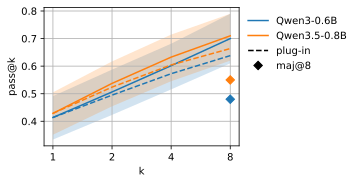

In [31]:
ax = d2l.plot_intervals(
    K, {m[5:]: tuple(np.array([est[m, k] for k in K]).T) for m in PAIR},
    'k', 'pass@k', kind='band', xscale='log2', marks={
        'plug-in': ('--', {m[5:]: (K, [est[m, k, 'plug-in'] for k in K])
                           for m in PAIR}),
        'maj@8': ('D', {m[5:]: ([8], [est[m, 'maj'][0]]) for m in PAIR})})
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=False);

<!-- d2l:prose id=scoring-md-31 fw=all -->

#### Variance within and between Problems

The bands in the plot are wide, about eight points to either side. Would more
samples per problem narrow them? The mean of $\hat U_i$ over $M$ problems is
uncertain for two reasons. Each $\hat U_i$ rests on only $n$ samples of
problem $i$, and the problems differ in difficulty and we drew only $M$ of
them. If $p_i$ is the probability that a sample solves problem $i$, the law
of total variance (that section) separates
the two:

$$
\textrm{Var}\Bigl[\frac{1}{M} \sum_{i=1}^{M} \hat U_i\Bigr]
= \frac{1}{M} \Bigl( \mathbb{E}\bigl[\textrm{Var}[\hat U_i \mid p_i]\bigr]
+ \textrm{Var}\bigl[1 - (1-p_i)^k\bigr] \Bigr).
$$

The first term is the equation averaged over the problems. It is
the variance *within* problems, and it shrinks as $n$ grows. The second is
the variance *between* problems and does not depend on $n$ at all. The cell
estimates the total from the spread of the $\hat U_i$ and the within part
from the formula. For $k = 1$ the within variance of problem $i$ is $p_i
(1-p_i)/n$. With $\hat p_i = c_i/n$ the quantity $\hat p_i (1 - \hat
p_i)/(n-1)$ estimates it without bias, which is why the code divides by 7 and
not by 8. For $k = 4$ the cell puts $\hat p_i$ in the place of $p_i$, which
is only approximately right.

In [32]:
shares = []
for m in PAIR:
    solved = pool[pool.model == m].groupby('problem_id').solved.sum()
    M, p = len(solved), solved.to_numpy() / 8
    for k in (1, 4):
        total = d2l.pass_at_k(8, solved.to_numpy(), k).var(ddof=1) / M
        within = (p * (1 - p) / 7 if k == 1 else  # unbiased at k = 1
                  np.array([d2l.pass_at_k_variance(8, q, k) for q in p])
                  ).mean() / M
        shares.append(dict(model=m[5:], k=k, total=f'{total:.2e}',
                           within=f'{within:.2e}',
                           between=f'{total - within:.2e}',
                           within_share=f'{within / total:.2f}',
                           within_estimate='exact' if k == 1 else 'plug-in'))
print(pd.DataFrame(shares).to_string(index=False))

       model  k    total   within  between within_share within_estimate
  Qwen3-0.6B  1 1.63e-03 1.16e-04 1.52e-03         0.07           exact
  Qwen3-0.6B  4 1.85e-03 2.62e-04 1.59e-03         0.14         plug-in
Qwen3.5-0.8B  1 1.51e-03 1.36e-04 1.38e-03         0.09           exact
Qwen3.5-0.8B  4 1.87e-03 2.27e-04 1.64e-03         0.12         plug-in


<!-- d2l:prose id=scoring-md-32 fw=all -->

Sampling accounts for about a tenth of the variance. The rest comes from
which 100 problems we happened to draw. Eight samples per problem were
already more than this question needed: eighty would narrow the bands by a
few percent, and twice as many problems by almost a third. A pool is worth
its samples for other reasons, since pass@k needs at least $k$ of them and a
vote needs several. Exercise 5 works out how to
divide a budget between samples and problems.

### Execution Checks

pass@k was made for programs, and so far we have applied it to arithmetic.
For a program the comparison with a key gives way to something stronger: we
run the program against tests. `d2l.run_python_tests` writes a program and
its tests into an empty temporary directory and runs them in a fresh Python
process, with a time limit and, where the operating system provides them,
limits on CPU time and memory. It returns `True` if the tests ran to their
end without an error.

In [33]:

def run_python_tests(program, test_code, timeout=5.0):
    """True iff program followed by test_code runs to its end and the
    process exits with code 0, in a fresh `python -I` process, in an empty
    temporary directory, with stdin closed, within timeout seconds of
    wall-clock time and, on POSIX, within limits on CPU time and address
    space (1 GiB). Exiting early (sys.exit, os._exit, a unittest.main() of
    the program's own) fails, as in human-eval; on POSIX, any process the
    code started is killed when the call returns. This is not a sandbox:
    the code runs as the caller, can read and write the caller's files and
    reach the network. Run code you did not write in a container."""
    import secrets
    import subprocess
    import tempfile
    token = secrets.token_hex(16)  # written only once test_code has run
    with tempfile.TemporaryDirectory() as tmp:
        with open(os.path.join(tmp, 'main.py'), 'w') as f:
            f.write(program + '\n' + test_code + '\n')
        done = os.path.join(tmp, 'done')  # absolute: the code may chdir
        proc = subprocess.Popen(
            [sys.executable, '-I', '-c', d2l._run_limits(timeout) +
             "import runpy\nrunpy.run_path('main.py', run_name='__main__')\n"
             f'open({done!r}, "w").write({token!r})'],
            cwd=tmp, stdin=subprocess.DEVNULL, stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL, start_new_session=os.name == 'posix')
        try:
            if proc.wait(timeout=timeout) != 0:
                return False
            with open(done) as f:
                return f.read() == token
        except (subprocess.TimeoutExpired, OSError):
            return False
        finally:
            d2l._kill_session(proc)

<!-- d2l:prose id=scoring-md-33 fw=all -->

Four hand-written versions of a function `add` show the four outcomes.

In [34]:
add = 'def add(a, b):\n    return a + b'
tests = 'assert add(2, 3) == 5\nassert add(-1, 1) == 0'
programs = {'correct': add,
            'wrong': 'def add(a, b):\n    return a - b',
            'infinite loop': 'def add(a, b):\n    while True:\n        pass',
            'syntax error': 'def add(a, b)\n    return a + b'}
timeout = 5.0
for name, program in programs.items():
    tic = time.time()
    ok = d2l.run_python_tests(program, tests, timeout=timeout)
    elapsed = time.time() - tic
    print(f'{name:14s} passed={ok!s:5s}' + (  # only the loop runs long
        f' stopped after {elapsed:.0f} s' if name == 'infinite loop' else ''))
    assert ok == (name == 'correct') and elapsed < timeout + 1

correct        passed=True 
wrong          passed=False


infinite loop  passed=False stopped after 5 s
syntax error   passed=False


<!-- d2l:prose id=scoring-md-34 fw=all -->

The correct program passes, the wrong one fails an assertion, the syntax
error fails before any test runs, and the infinite loop is stopped after five
seconds.

Note what the function does not do. The program runs with our rights: it can
read our files, delete them and open network connections, and a time limit
protects against none of that. For this reason the notebook runs only
programs that we wrote ourselves. Code written by a model belongs in a
container or a virtual machine
(Exercise 10). The authors of HumanEval, the
benchmark that made pass@k a standard, released their harness in 2021 with
its execution line commented out and a warning in its place
[@Chen.Tworek.Jun.ea.2021].

### Reasoning before Answering

The likelihood of a letter measures what a model would say at once, with no
room to think. The post-trained checkpoints were trained to do otherwise: to
write their way to an answer and, with thinking on, to deliberate first
inside a think block (that section). A score that never lets
such a model write may misjudge it. So we also let the models answer the ARC
items in text, in two *arms*. In both, the model receives the item in the
letter layout as a user message that ends with the request to put the letter
of the correct option inside `\boxed{}`.

In the *direct* arm thinking is off and decoding is greedy, which gives one
reply per item and needs no seed. All three post-trained checkpoints answer
all 500 items. In the *reasoning* arm thinking is on, and replies are sampled
with the settings that the Qwen3 model cards recommend for thinking. The
cards advise against greedy decoding in that mode. The arms thus differ in
decoding as well as in thinking: we compare two ways of using a model, and
not the effect of the think block alone. Qwen3-0.6B and Qwen3-1.7B answer the
first 100 items in this arm, fewer because reasoning is expensive.
Qwen3.5-0.8B stays out of it: its model card warns that with thinking on,
this smallest model of its family is prone to loops of thought from which it
does not return.

Each arm has a token budget, 1,024 new tokens for a direct reply and 4,096
for a reasoning one, and the budgets belong to the convention like everything
else. They are set so that few replies reach them. A reply that does reach
its budget has not finished, and `boxed_letter` treats it as committing to no
answer, whatever boxes it may contain.

In [35]:
ASK = 'Put the letter of the correct option inside \\boxed{}.'
ARC_CHAT = [d2l.format_mc(q, o, 'letter')[0].removesuffix('Answer:') + ASK
            for _, q, o, _ in ARC]
# The budgets belong to the convention, and they are set so that few
# replies reach them: with thinking off the models still explain before the
# box, and with thinking on they deliberate for up to a few thousand tokens
ARMS = {  # arm: (models, subset items, batch size, settings of generate)
    'direct': ([PAIR[0], PAIR[1], 'Qwen/Qwen3-1.7B'], 500, 50, dict(
        strategy='greedy', enable_thinking=False, max_new_tokens=1024)),
    'reasoning': ([PAIR[0], 'Qwen/Qwen3-1.7B'], 100, 25, dict(
        strategy='sample', temperature=0.6, p=0.95, k=20, seed=0,
        enable_thinking=True, max_new_tokens=4096))}

def boxed_letter(text, n_options, finished=True):
    """The option a finished reply commits to in its last \\boxed{} after
    any thinking, or None; a reply cut at its token budget commits to none."""
    if not finished:
        return None
    s = d2l.extract_answer(text.split('</think>')[-1], 'boxed') or ''
    m = re.match(r'(?:\\text\{)?\(?([A-Z])(?![A-Za-z])', s)
    return m[1] if m and ord(m[1]) - ord('A') < n_options else None

<!-- d2l:prose id=scoring-md-35 fw=all -->

The next cell reads the registered replies and summarizes them. A reply is
*invalid* if it finished without a readable letter in a box, and *truncated*
if it reached the budget. Both count as wrong in the accuracy, and the column
`among parsed` gives the accuracy of the replies that remain.

In [36]:
if 'arc-generations' in RERUN:
    records, tic = [], time.time()
    for m in dict.fromkeys(ARMS['direct'][0] + ARMS['reasoning'][0]):
        model, tok = d2l.load_hf(m)
        for arm, (models, n, size, settings) in ARMS.items():
            if m in models:
                out = d2l.generate(model, tok, ARC_CHAT[:n], chat=True,
                                   batch_size=size, **settings)
                letters = [boxed_letter(g.text, len(it[2]),
                                        g.finish_reason != 'length')
                           for it, g in zip(ARC, out)]
                records += [dict(
                    model=m, revision=d2l.HF_REVISIONS[m], arm=arm,
                    item_id=it[0], settings=settings, batch_size=size,
                    seed=settings.get('seed'), text=g.text,
                    n_tokens=len(g.token_ids), finish_reason=g.finish_reason,
                    letter=a, correct=a == 'ABCDE'[it[3]])
                    for it, g, a in zip(ARC, out, letters)]
        del model
        d2l.lm_free()
    print(f'{len(records):,} replies in {(time.time() - tic) / 60:.1f} min, '
          f'{d2l.lm_peak()}')
    d2l.lm_save_rerun(ARTIFACTS['arc-generations'][1],
                      lambda path: d2l.write_jsonl(path, records))
arc_gen = d2l.read_jsonl(result('arc-generations'))
for arm, (models, n, size, settings) in ARMS.items():  # as the file records
    d = arc_gen[arc_gen.arm == arm]
    assert (d.groupby('model').size() == n).all() and set(d.model) == set(
        models) and (d.batch_size == size).all(), arm
    assert all(s == settings for s in d.settings), arm
    print(f'{arm}: {n} items per model, batch {size}, settings:')
    print(textwrap.fill(', '.join(f'{k}={v}' for k, v in settings.items()),
                        79, initial_indent='    ', subsequent_indent='    '))
at_cap = arc_gen.finish_reason == 'length'
replies = arc_gen.assign(model=arc_gen.model.str.removeprefix('Qwen/'),
                         invalid=arc_gen.letter.isna() & ~at_cap,
                         truncated=at_cap)
summary = replies.groupby(['model', 'arm'])
print(pd.DataFrame({
    'accuracy': summary.correct.mean().round(3),
    'among parsed': replies[replies.letter.notna()].groupby(
        ['model', 'arm']).correct.mean().round(3),
    'invalid': summary.invalid.mean().round(3),
    'truncated': summary.truncated.mean().round(3),
    'mean tokens': summary.n_tokens.mean().round(0)}).to_string())

direct: 500 items per model, batch 50, settings:
    strategy=greedy, enable_thinking=False, max_new_tokens=1024
reasoning: 100 items per model, batch 25, settings:
    strategy=sample, temperature=0.6, p=0.95, k=20, seed=0,
    enable_thinking=True, max_new_tokens=4096
                        accuracy  among parsed  invalid  truncated  mean tokens
model        arm                                                               
Qwen3-0.6B   direct        0.516         0.572    0.098      0.000         98.0
             reasoning     0.670         0.670    0.000      0.000       1019.0
Qwen3-1.7B   direct        0.788         0.821    0.036      0.004        241.0
             reasoning     0.830         0.838    0.000      0.010       1321.0
Qwen3.5-0.8B direct        0.714         0.760    0.000      0.060        390.0


<!-- d2l:prose id=scoring-md-36 fw=all -->

Invalid and truncated replies have to do with following an instruction and
with our budget, not with science, and they are not rare. About 10% of the
direct replies of Qwen3-0.6B never put a letter in a box, and 6% of those of
Qwen3.5-0.8B are still explaining when their 1,024 tokens run out. Its
accuracy of 0.71 counts them as wrong. Note also that "direct" does not mean
short. With thinking off the models still explain themselves before the box,
in 100 to 400 tokens on average.

A reasoning reply takes more than a thousand tokens where a scored letter
takes one, and both models that reason score higher in that arm than in the
direct one. Is the difference real? The two rows of a model cover different
items, 100 against 500, so this table cannot say. We make the comparison
item by item in that section, once all verdicts are
in one place.

## Rankings under Different Conventions

We now hold every piece: four rules for a cloze score, the letter format with
and without demonstrations, and two generative arms. Let us put the five
checkpoints through the likelihood conventions on the same 500 items, and the
post-trained ones through the generative arms as well, and ask the question
of the opening: which of two models is better? Our pair is Qwen3-0.6B against
Qwen3.5-0.8B. We also fix one further comparison now, before looking, for
the case that no convention reverses their order. Is the gap between the
two models the same under the letter format without demonstrations as under
the cloze sum, the two ends of likelihood scoring? With eight conventions one can always find a pair of columns that looks
interesting afterwards. Naming the comparison first is what lets its interval
mean what it says.

### The Convention Grid

`CONVENTIONS` lists the eight by name: the cloze format under the sum, per
token, per character and with the PMI correction, the letter format without
demonstrations and with our five (`letter-0` and `letter-5`), and the two
generative arms. The likelihood conventions show
every checkpoint plain text without a chat template, post-trained ones
included. This is what harnesses do, and it gives a base model and its
post-trained twin the same input. The first cell is plumbing again: two
helpers that move between the output of the scorer and a table with one row
per item and choice, the form in which the scores are stored.

In [37]:
def score_long(model, tok, model_id, fmt, batch_size=8):
    """Components of every choice of the 500 items in format fmt, one row
    per (item, choice), as the artifact lm-arc-scores stores them."""
    prompts, choices = zip(*FORMATS[fmt])
    c = d2l.score_choices(model, tok, prompts, choices,
                          batch_size=batch_size, return_components=True)
    i, j = np.nonzero(c.n_tokens.numpy())
    return pd.DataFrame({
        'model': model_id, 'revision': d2l.HF_REVISIONS[model_id],
        'fmt': fmt, 'item_id': np.array(ARC_IDS)[i], 'choice': j,
        'gold': GOLD[i],
        **{f: v.numpy()[i, j] for f, v in c._asdict().items()}})

def matrix(arc, model, fmt, col='ll'):
    """(items, 5) array of one column, in subset order; nan beyond an
    item's options."""
    d = arc[(arc.model == model) & (arc.fmt == fmt)]
    return d.pivot(index='item_id', columns='choice', values=col).reindex(
        index=ARC_IDS, columns=range(5)).to_numpy(float)

<!-- d2l:prose id=scoring-md-37 fw=all -->

Each likelihood convention is then one line of arithmetic on the stored
columns. `predict` takes the first of the largest scores, and `margin` is the
distance between the best score of an item and the runner-up.

In [38]:
CONVENTIONS = ['cloze-sum', 'cloze-token', 'cloze-char', 'cloze-PMI',
               'letter-0', 'letter-5', 'gen-direct', 'gen-reasoning']
CLOZE = {'cloze-sum': None, 'cloze-token': 'n_tokens',
         'cloze-char': 'n_chars', 'cloze-byte': 'n_bytes'}

def convention_scores(arc, model, conv, col='ll'):
    """Scores (items, 5) of a likelihood convention, nan beyond options."""
    if conv in CLOZE:
        s = matrix(arc, model, 'cloze', col)
        return s if CLOZE[conv] is None else s / matrix(arc, model, 'cloze',
                                                        CLOZE[conv])
    if conv == 'cloze-PMI':  # minus log P(choice | 'Answer:')
        return (matrix(arc, model, 'cloze', col) -
                matrix(arc, model, 'uncond', col))
    return matrix(arc, model, {'letter-0': 'letter0',
                               'letter-5': 'letter5'}[conv], col)

def predict(s):  # first index of the largest score, as score_choices
    return np.nan_to_num(s, nan=-np.inf).argmax(1)

def margin(s):  # best minus second-best score
    top = -np.sort(-np.nan_to_num(s, nan=-np.inf), axis=1)
    return top[:, 0] - top[:, 1]

<!-- d2l:prose id=scoring-md-38 fw=all -->

The scores of the grid are registered. On a GPU the next cell computes all of
them again, in bf16 at batch size 8, and counts the predictions that equal
the registered ones.

In [39]:
key = ARTIFACTS['arc-scores'][0]
path = d2l.lm_registered(key)
reg = None if path is None else pd.read_parquet(path)
if GPU:
    parts = []
    for m in MODELS:
        model, tok = d2l.load_hf(m)
        parts.append(pd.concat([score_long(model, tok, m, fmt)
                                for fmt in FORMATS]))
        del model
        d2l.lm_free()
        print(f'{m[5:]}: {d2l.lm_peak()}')
        if reg is None:
            continue
        same = {}  # predictions as registered, per format
        for fmt in FORMATS:
            new, old = matrix(parts[-1], m, fmt), matrix(reg, m, fmt)
            bad = np.flatnonzero(predict(new) != predict(old))
            same[fmt] = len(ARC) - len(bad)
            for i in bad:
                print(f'    {fmt}: {ARC_IDS[i]} differs from {key} '
                      f'(margin there {margin(old)[i]:.3f})')
        print('    predictions as registered: ' + ', '.join(
            f'{fmt} {n}/{len(ARC)}' for fmt, n in same.items()))
    scores = pd.concat(parts, ignore_index=True)
else:
    print(f'no GPU: the grid is read from {key}')

Qwen/Qwen3-0.6B-Base@da87bfb608c1: Qwen3ForCausalLM, stop tokens [151643]
0 missing keys; unexpected keys: none
kernels: attention sdpa


Qwen3-0.6B-Base: peak 4.3 GiB (4.7 GiB reserved)
    predictions as registered: cloze 500/500, uncond 500/500, letter0 500/500, letter5 500/500


Qwen/Qwen3-0.6B@c1899de289a0: Qwen3ForCausalLM, stop tokens [151645, 151643]
0 missing keys; unexpected keys: none
kernels: attention sdpa


Qwen3-0.6B: peak 1.9 GiB (2.0 GiB reserved)
    predictions as registered: cloze 500/500, uncond 500/500, letter0 500/500, letter5 500/500


Qwen/Qwen3.5-0.8B-Base@dc7cdfe2ee41: Qwen3_5ForCausalLM, stop tokens [248044]
0 missing keys; unexpected keys: none
kernels: attention sdpa, delta rule fla, short convolution PyTorch


Qwen3.5-0.8B-Base: peak 2.8 GiB (2.8 GiB reserved)
    predictions as registered: cloze 500/500, uncond 500/500, letter0 500/500, letter5 500/500


Qwen/Qwen3.5-0.8B@2fc06364715b: Qwen3_5ForCausalLM, stop tokens [248044, 248046]
0 missing keys; unexpected keys: none
kernels: attention sdpa, delta rule fla, short convolution PyTorch


Qwen3.5-0.8B: peak 2.8 GiB (2.8 GiB reserved)
    predictions as registered: cloze 500/500, uncond 500/500, letter0 500/500, letter5 500/500


Qwen/Qwen3-1.7B@70d244cc86cc: Qwen3ForCausalLM, stop tokens [151645, 151643]
0 missing keys; unexpected keys: none
kernels: attention sdpa


Qwen3-1.7B: peak 4.6 GiB (5.0 GiB reserved)
    predictions as registered: cloze 500/500, uncond 500/500, letter0 500/500, letter5 500/500


<!-- d2l:prose id=scoring-md-39 fw=all -->

Below the loader's reports, all 500 predictions of every checkpoint in every
format equal the registered ones. At a fixed batch size, on the same hardware
and software, likelihood scoring repeats itself. Now we change the batch
size.

### Batch Size as Part of the Convention

Floating-point addition is not associative, so a sum depends on the order of
its terms (that section), and a GPU kernel
chooses that order by the shape of its input
(that section). The shape of a batch is such an input.
In bf16, where every product is rounded to eight significant bits, the hidden
state of an item therefore depends a little on the items it is batched with,
and that section saw log-probabilities move by a tenth of
a nat for this reason. Does that change answers? We score the pair once more
at batch size 1, and Qwen3-0.6B also in fp32 at both batch sizes. For each
setting the table gives the number of the 500 predictions that changed, the
largest change of a score, and the number of items whose margin is smaller
than that change.

In [40]:
BATCH_RUNS = [  # model, dtype, batch size, column of the re-scoring
    (PAIR[0], torch.bfloat16, 1, 'll_bs1'),
    (PAIR[1], torch.bfloat16, 1, 'll_bs1'),
    (PAIR[0], torch.float32, 1, 'll_fp32_bs1'),
    (PAIR[0], torch.float32, 8, 'll_fp32_bs8')]
if 'arc-scores' in RERUN:
    assert ieee_fp32()
    on, extra, tic = ['model', 'fmt', 'item_id', 'choice'], {}, time.time()
    for m, dtype, size, col in BATCH_RUNS:
        model, tok = d2l.load_hf(m, dtype=dtype)
        extra.setdefault(col, []).extend(
            score_long(model, tok, m, fmt, size)[on + ['ll']].rename(
                columns={'ll': col}) for fmt in ('cloze', 'letter0'))
        del model
        d2l.lm_free()
    print(f'{len(BATCH_RUNS)} re-scorings in {(time.time() - tic) / 60:.1f} '
          f'min, {d2l.lm_peak()}')
    for col, parts in extra.items():
        scores = scores.merge(pd.concat(parts), on=on, how='left')
    d2l.lm_save_rerun(ARTIFACTS['arc-scores'][1],
                      lambda path: scores.to_parquet(path, index=False))
arc = pd.read_parquet(result('arc-scores'))
drift_rows = []
for name, m, a, b in [('bf16, batch 8 vs 1', PAIR[0], 'll', 'll_bs1'),
                      ('bf16, batch 8 vs 1', PAIR[1], 'll', 'll_bs1'),
                      ('fp32, batch 1 vs 8', PAIR[0], 'll_fp32_bs1',
                       'll_fp32_bs8')]:
    for conv in ('cloze-sum', 'letter-0'):
        sa, sb = (convention_scores(arc, m, conv, c) for c in (a, b))
        change = np.nanmax(np.abs(sa - sb))
        changed = predict(sa) != predict(sb)  # count, and rate of 500
        drift_rows.append(dict(setting=name, model=m[5:], convention=conv,
                               changed=changed.sum(),
                               rate=round(float(changed.mean()), 3),
                               max_change=f'{change:.2g}',
                               below_change=(margin(sa) < change).sum()))
print(pd.DataFrame(drift_rows).to_string(index=False))

           setting        model convention  changed  rate max_change  below_change
bf16, batch 8 vs 1   Qwen3-0.6B  cloze-sum        6 0.012        1.1           144
bf16, batch 8 vs 1   Qwen3-0.6B   letter-0       12 0.024       0.78           150
bf16, batch 8 vs 1 Qwen3.5-0.8B  cloze-sum        1 0.002       0.35            55
bf16, batch 8 vs 1 Qwen3.5-0.8B   letter-0        7 0.014       0.27            95
fp32, batch 1 vs 8   Qwen3-0.6B  cloze-sum        0 0.000    0.00012             0
fp32, batch 1 vs 8   Qwen3-0.6B   letter-0        0 0.000    0.00013             0


<!-- d2l:prose id=scoring-md-40 fw=all -->

In bf16 between 1 and 12 of the 500 predictions change with the batch size,
up to about 2%. Single scores move by up to 1.1 nats under the cloze sum and
by up to 0.8 for a single letter, and from 55 to 150 items have a margin
below the largest change, so any of them might have changed. In fp32 the
scores move in the fourth decimal and no prediction changes.

The batch size therefore belongs to the convention, next to the precision.
Where single predictions must repeat from one batching to the next, fp32 is
the cure, at twice the memory and without the fused kernels. In bf16 we need
an allowance instead: a difference between two models that is no larger than
this *batch drift* must not be read as a difference.

A likelihood score is thus tied to its call. The same items in the same
batches gave us the same predictions twice. At another batch size, or among
other items, the predictions agree only up to the drift. Generated text adds
a complication: after the first token that a batch changes, greedy decoding
continues along another path. We did not generate at two batch sizes, so for
the generative conventions the drift of the likelihood scores has to stand
in.

For the comparison of our pair we need the drift of a difference in
accuracy. The cell computes how far the difference of the pair moves between
batch sizes 8 and 1 under the four conventions that we scored twice, and
gives the largest value to the conventions that we did not.

In [41]:
def pair_difference(conv, col):
    acc = [(predict(convention_scores(arc, m, conv, col)) == GOLD).mean()
           for m in PAIR]
    return acc[1] - acc[0]

measured = {conv: abs(pair_difference(conv, 'll') -
                      pair_difference(conv, 'll_bs1'))
            for conv in ('cloze-sum', 'cloze-token', 'cloze-char',
                         'letter-0')}
DRIFT = {c: measured.get(c, max(measured.values())) for c in CONVENTIONS}
print('drift of the pair difference, batch 8 vs 1:')
print(pd.Series(measured).round(3).to_string())
print('not re-scored at batch 1, so given the largest:',
      ', '.join(c for c in CONVENTIONS if c not in measured))

drift of the pair difference, batch 8 vs 1:
cloze-sum      0.004
cloze-token    0.004
cloze-char     0.002
letter-0       0.010
not re-scored at batch 1, so given the largest: cloze-PMI, letter-5, gen-direct, gen-reasoning


<!-- d2l:prose id=scoring-md-41 fw=all -->

The difference of the pair moves by 0.2 to 1.0 points. From here on, one
model counts as ahead of the other only if the nearer end of the interval
lies further from zero than this.

### Accuracy under Eight Conventions

`CORRECT` holds one verdict per item, right or wrong, for every checkpoint
and convention. The cell that fills it prints nothing.

In [42]:
def gen_column(model, arm, col):
    """One column of a generative arm per subset item (nan if not run)."""
    d = arc_gen[(arc_gen.model == model) & (arc_gen.arm == arm)]
    return d.set_index('item_id')[col].reindex(ARC_IDS)

def correct(model, conv):
    """1 or 0 per subset item; nan where the convention did not run."""
    if conv.startswith('gen-'):
        return gen_column(model, conv[4:], 'correct').to_numpy(float)
    return (predict(convention_scores(arc, model, conv)) == GOLD
            ).astype(float)

CORRECT = {(m, c): correct(m, c) for m in MODELS for c in CONVENTIONS}

<!-- d2l:prose id=scoring-md-42 fw=all -->

Before any average, one item. The cell looks for the first of the 500 on
which Qwen3-0.6B names three different letters under the cloze sum, the
letter format and the direct arm.

In [43]:
m = PAIR[0]
verdicts = pd.DataFrame({
    'cloze-sum': [chr(65 + i) for i in predict(convention_scores(
        arc, m, 'cloze-sum'))],
    'letter-0': [chr(65 + i) for i in predict(convention_scores(
        arc, m, 'letter-0'))],
    'gen-direct': gen_column(m, 'direct', 'letter').to_numpy()})
committed = verdicts['gen-direct'].notna().to_numpy()  # a parsed reply
n_verdicts = np.where(committed, verdicts.nunique(axis=1), 0)
rule = 3 if (n_verdicts == 3).any() else 2  # three letters, else two
assert (n_verdicts >= rule).any(), 'no item with two different letters'
i = int(np.argmax(n_verdicts >= rule))
_, q, opts, gold = ARC[i]
for line in [q] + [f'{a}. {o}' for a, o in zip('ABCDE', opts)]:
    print(textwrap.fill(line, 79, subsequent_indent='   '))
print(f'gold {"ABCDE"[gold]}; Qwen3-0.6B: ' + ', '.join(
    f'{k} {v}' for k, v in verdicts.iloc[i].items()))
print(f'the first item with {rule} different letters: {ARC_IDS[i]}')
print(f'items with at least two: {(n_verdicts > 1).sum()} of the '
      f'{committed.sum()} with a parsed direct reply')

A farmer thinks that the vegetables on her farm are not getting enough water.
   Her son suggests that they use water from the nearby ocean to water the
   vegetables. Is this a good idea?
A. Yes, because there is plenty of ocean water.
B. Yes, because ocean water has many natural fertilizers.
C. No, because ocean water is too salty for plants grown on land.
D. No, because ocean water is much more polluted than rainwater.
gold C; Qwen3-0.6B: cloze-sum D, letter-0 B, gen-direct C
the first item with 3 different letters: NAEP_2005_4_S13+14
items with at least two: 352 of the 451 with a parsed direct reply


<!-- d2l:prose id=scoring-md-43 fw=all -->

A farmer wonders whether to water her vegetables from the ocean. Scored by
the probability of the answer texts, Qwen3-0.6B says D. Scored by letters it
says B. Asked to write, it says C, which is correct. This item is no
curiosity. Of the 451 items on which the direct reply states a letter, 352
receive at least two different answers under the three conventions, more
than three in four. "What does the model answer?" is a question about a model
and a convention together.

Now the averages. The table gives the accuracy of each checkpoint under each
convention, followed by half the width of its 95% interval over items. Its
last row is a quantity of another kind, the bits per byte of the correct
option, to which we come back.

In [44]:
ACC = {key: boot(c[~np.isnan(c)]) for key, c in CORRECT.items()
       if not np.isnan(c).all()}

def option_bpb(model):
    """(items, 5) bits per byte of every option in the cloze format, nan
    beyond an item's options: the log-probability of the option's tokens,
    its leading space included, over the bytes of the option text without
    that space (the harness's acc_bytes length)."""
    return -matrix(arc, model, 'cloze') / (
        matrix(arc, model, 'cloze', 'n_bytes') * math.log(2))

BPB_OPT = {m: option_bpb(m) for m in MODELS}
BPB_GOLD = {m: b[np.arange(len(ARC)), GOLD] for m, b in BPB_OPT.items()}
SHORT = {m: m[5:].replace('Qwen', 'Q') for m in MODELS}  # Q3-0.6B-Base

def plus_minus(e):  # the estimate and half the width of its interval
    return f'{e[0]:.3f} ±{(e[2] - e[1]) / 2:.3f}'

table = pd.DataFrame({SHORT[m]: {
    c: plus_minus(ACC[m, c]) for c in CONVENTIONS if (m, c) in ACC}
    for m in MODELS}).reindex(CONVENTIONS).fillna('')
table.loc['gold bpb'] = [plus_minus(boot(BPB_GOLD[m])) for m in MODELS]
print('accuracy (gold bpb: mean bits per byte of the gold option), with')
print('half the width of the 95% bootstrap interval over items:')
print(table.to_string())
print("predictions where 'char' and 'byte' differ, five checkpoints:",
      sum((predict(convention_scores(arc, m, 'cloze-char')) != predict(
          convention_scores(arc, m, 'cloze-byte'))).sum() for m in MODELS))

accuracy (gold bpb: mean bits per byte of the gold option), with
half the width of the 95% bootstrap interval over items:
               Q3-0.6B-Base       Q3-0.6B Q3.5-0.8B-Base     Q3.5-0.8B       Q3-1.7B
cloze-sum      0.330 ±0.041  0.294 ±0.041   0.350 ±0.042  0.288 ±0.040  0.392 ±0.044
cloze-token    0.358 ±0.042  0.318 ±0.040   0.382 ±0.042  0.326 ±0.041  0.414 ±0.044
cloze-char     0.378 ±0.042  0.320 ±0.040   0.354 ±0.042  0.334 ±0.042  0.420 ±0.044
cloze-PMI      0.414 ±0.044  0.362 ±0.042   0.420 ±0.044  0.392 ±0.043  0.460 ±0.043
letter-0       0.604 ±0.042  0.502 ±0.044   0.686 ±0.041  0.612 ±0.043  0.724 ±0.039
letter-5       0.662 ±0.041  0.588 ±0.044   0.684 ±0.041  0.664 ±0.042  0.758 ±0.037
gen-direct                   0.516 ±0.044                 0.714 ±0.039  0.788 ±0.036
gen-reasoning                0.670 ±0.090                               0.830 ±0.075
gold bpb       1.379 ±0.096  1.352 ±0.074   1.152 ±0.075  1.197 ±0.070  1.303 ±0.086
predictions where 'char' and

<!-- d2l:prose id=scoring-md-44 fw=all -->

Read the column of Qwen3-1.7B from top to bottom. Under the cloze sum it
answers 39% of the questions correctly, not far above the 25% of guessing.
Under the letter format it is right on 72%, with five demonstrations on 76%,
when it writes its answer on 79%, and when it reasons first, on 83% of the
first 100 items. Nothing about the model changed between these numbers. A
temperature of 39 is a fever in Celsius and a cold morning in Fahrenheit, and
nobody reports one without the scale. A benchmark accuracy needs its
convention in the same way.

The other columns have the same shape. Within the cloze family PMI is the
highest score in every column, 7 to 10 points above the sum, which agrees
with its use for this dataset by GPT-3 and OLMES. The rates per token and
per character lie 0 to 5 points above the sum, and the whole family stays at
or below 0.46. Which of these gains are real? The intervals of the table
belong to single accuracies and cannot say. Two rules applied to the same
items call for a paired comparison, and we make it below. (The rates per
character and per byte differ on 2 of the 2,500 predictions, so the table
lists only the first.) The letter format lies 21 to 34 points above the
cloze sum for every checkpoint, the base models included.

Why so much? Look at what the two prompts contain. The cloze prompt never
shows the options. The model must give a high probability to the text of
the correct answer without knowing what it competes with, and a question
such as the farmer's, "Is this a good idea?", is hardly a question without
its four answers. The letter prompt shows all four and asks for a choice
among them, which is the task that the authors of the exam set. The table
cannot say how much of the gap this accounts for. It does say that these
small models bind letters to options, and that the finding of
@Robinson.Rytting.Wingate.2023 describes the models of its time.

Under the cloze sum the five checkpoints lie between 29% and 39%, close to
each other and not far from guessing, and a convention like that has little
room to separate models. For a multiple-choice benchmark with short options
and current models the letter format is therefore the one to use. OLMES
arrives at the same place by another route: it scores both formats and
reports the better one.

One more pattern is in the table. Under the likelihood conventions each
post-trained checkpoint scores at or below its base twin. These conventions
present plain text, the input a base model was trained on. We had not
planned this comparison, so we record it and build nothing on it.

### The Pair under Seven Conventions

Does the convention decide which model of our pair is ahead? The answer
takes three steps: the difference of the pair under each convention, a look
at a smoother score than accuracy, and the comparison that we fixed
beforehand. For each convention that both models ran, the next cell computes
the paired difference in accuracy, Qwen3.5-0.8B minus Qwen3-0.6B, with its
interval, and names a model as ahead only if the interval clears zero by
more than the drift.

In [45]:
def paired(a, b):  # mean of a - b on the items both cover, with interval
    ok = ~(np.isnan(a) | np.isnan(b))
    return boot(a[ok], b[ok])

PAIR_CONVS = CONVENTIONS[:7]  # the conventions both models ran
PAIR_DIFF = {c: paired(CORRECT[PAIR[1], c], CORRECT[PAIR[0], c])
             for c in PAIR_CONVS}  # Qwen3.5-0.8B minus Qwen3-0.6B
ahead = {c: PAIR[1][5:] if lo > DRIFT[c] else PAIR[0][5:] if hi < -DRIFT[c]
         else 'neither' for c, (_, lo, hi) in PAIR_DIFF.items()}
print(pd.DataFrame({
    'difference': {c: show(e) for c, e in PAIR_DIFF.items()},
    'drift': {c: f'{DRIFT[c]:.3f}' + ('' if c in measured else ' (max)')
              for c in PAIR_CONVS},
    'ahead': ahead}).to_string())
print('ranking flips:', len(set(ahead.values()) - {'neither'}) == 2)
both = np.ones(len(ARC), bool)  # both direct replies commit to a letter
for m in PAIR:
    both &= gen_column(m, 'direct', 'letter').notna().to_numpy()
sub = [CORRECT[m, 'gen-direct'][both] for m in PAIR]
print(f'gen-direct on the {both.sum()} items where both replies commit: '
      f'{sub[0].mean():.3f} and {sub[1].mean():.3f},\n    difference '
      f'{show(boot(sub[1], sub[0]))}')
wrong = {}  # mean bpb of an item's wrong options
for m in PAIR:
    b = BPB_OPT[m].copy()
    b[np.arange(len(ARC)), GOLD] = np.nan
    wrong[m] = np.nanmean(b, 1)
print('Qwen3.5-0.8B - Qwen3-0.6B:')
for name, (d, lo, hi) in [
        ('cloze-char accuracy', PAIR_DIFF['cloze-char']),
        ('gold bpb', boot(BPB_GOLD[PAIR[1]], BPB_GOLD[PAIR[0]])),
        ('wrong-option bpb', boot(wrong[PAIR[1]], wrong[PAIR[0]])),
        ('wrong - gold bpb', boot(wrong[PAIR[1]] - BPB_GOLD[PAIR[1]],
                                  wrong[PAIR[0]] - BPB_GOLD[PAIR[0]]))]:
    print(f'    {name}: {show((d, lo, hi))}, |difference| over half-width '
          f'{abs(d) / ((hi - lo) / 2):.2f}')

                         difference        drift         ahead
cloze-sum    -0.006 [-0.044, 0.032]        0.004       neither
cloze-token   0.008 [-0.030, 0.046]        0.004       neither
cloze-char    0.014 [-0.024, 0.052]        0.002       neither
cloze-PMI     0.030 [-0.020, 0.080]  0.010 (max)       neither
letter-0       0.110 [0.062, 0.158]        0.010  Qwen3.5-0.8B
letter-5       0.076 [0.030, 0.122]  0.010 (max)  Qwen3.5-0.8B
gen-direct     0.198 [0.146, 0.250]  0.010 (max)  Qwen3.5-0.8B
ranking flips: False


gen-direct on the 424 items where both replies commit: 0.580 and 0.759,
    difference 0.179 [0.127, 0.233]
Qwen3.5-0.8B - Qwen3-0.6B:
    cloze-char accuracy: 0.014 [-0.024, 0.052], |difference| over half-width 0.37
    gold bpb: -0.155 [-0.194, -0.115], |difference| over half-width 3.94
    wrong-option bpb: -0.135 [-0.177, -0.094], |difference| over half-width 3.25
    wrong - gold bpb: 0.020 [-0.017, 0.057], |difference| over half-width 0.53


<!-- d2l:prose id=scoring-md-45 fw=all -->

For this pair the answer to the question of the opening is no: no convention
puts Qwen3-0.6B ahead. Under the four cloze conventions the two models cannot
be told apart, with differences between $-1$ and $+3$ points and intervals of
four or five points to either side. Under the letter format Qwen3.5-0.8B
leads by about 11 points without demonstrations, with an interval from 6 to
16, and by about 8 with them. In the direct arm it leads by about 20 points
(15 to 25). So the ranking does not flip, and something nearly as awkward
happens instead. Whether the two models differ at all, and by how much,
depends on the convention. A reader of a cloze leaderboard would call them
equal, and a reader of a generative one would see a gap of twenty points.

The gap in the direct arm carries a qualification that we know from
that section: it counts the replies of Qwen3-0.6B without
a box as wrong. The line after `ranking flips` therefore repeats the
comparison on the 424 items where both replies state a letter. There the two
models are right on 58% and 76%, a difference of about 18 points (13 to 23).
Most of the gap lies in the answers and not in the format.

The second step concerns the bottom row of the table and the last four
lines of this output. Accuracy turns each item into one bit, right or wrong,
and at the cloze accuracies of these models many of those bits are noise. A
smoother score is the *bits per byte of the gold option*: the negative cloze
log-probability of the correct answer in bits, divided by the bytes of its
text. It is a real number per item, and it moves long before a prediction
changes. Studies of small models and of benchmark noise recommend continuous
scores of this kind
[@Magnusson.Tai.Bogin.ea.2025; @Heineman.Hofmann.Magnusson.ea.2025].

Does it separate our pair? The output divides each difference by half the
width of its interval, so that a ratio above 1 means that the interval
excludes zero. For the accuracy per character the ratio is 0.4. For the gold
bits per byte it is 3.9: Qwen3.5-0.8B spends about 0.16 bits per byte less
on the correct options, far outside the noise.

Before we celebrate, look at the next line. It spends 0.14 bits per byte
less on the *wrong* options too. Qwen3.5-0.8B is simply better at predicting
the kind of text that ARC options are made of, right or wrong. What has to
do with knowing the answer is the gap between wrong and correct options, and
that gap separates the pair no better than accuracy did, with a ratio of
0.5. A smooth score is more sensitive, and we have to check what it is
sensitive to.

Now the third step, the comparison that we fixed before looking. For each
model `gain` is the paired difference between its accuracy under letter-0 and
under the cloze sum, and the question is whether the two models of the pair
gain differently. The cell also prints the gain of every checkpoint and
compares each post-trained checkpoint with its base twin. Its last table
makes the paired comparison that we postponed: each normalized cloze rule
against the cloze sum, for every checkpoint, in accuracy points.

In [46]:
def gain(m, col='ll'):  # letter-0 minus cloze-sum, correct per item
    return np.subtract(*((predict(convention_scores(arc, m, c, col)) ==
                          GOLD).astype(float)
                         for c in ('letter-0', 'cloze-sum')))

def verdict(e, drift, names, n=len(ARC)):  # nearer end beyond drift wins
    return (names[0] if e[1] > drift else names[1] if e[2] < -drift else
            f'not resolved at {n} items')

# Drift of these contrasts between batch sizes 8 and 1 (bf16), measured on
# the two models re-scored at batch 1; the largest stands for all of them
drift = max([abs(gain(m).mean() - gain(m, 'll_bs1').mean()) for m in PAIR]
            + [abs((gain(PAIR[1]) - gain(PAIR[0])).mean() -
                   (gain(PAIR[1], 'll_bs1') -
                    gain(PAIR[0], 'll_bs1')).mean())])
print(f'drift of the contrasts, batch 8 vs 1: {drift:.3f}')
e = boot(gain(PAIR[1]), gain(PAIR[0]))
print('pair, difference of (letter-0 - cloze-sum):')
print(f'    {show(e)} ('
      + verdict(e, drift, [m[5:] + ' gains more' for m in PAIR[::-1]]) + ')')
print('letter-0 - cloze-sum:')
for m in MODELS:
    e = boot(gain(m))
    print(f'    {m[5:]}: {show(e)} '
          f'({verdict(e, drift, ("letter-0 ahead", "cloze-sum ahead"))})')
print('post-trained - base, difference of (letter-0 - cloze-sum):')
for base, post in zip(BASES, PAIR):
    e = boot(gain(post), gain(base))
    print(f'    {post[5:]} - {base[5:]}: {show(e)}')
    print('        (' + verdict(e, drift, ('post-trained gains more',
                                          'base gains more')) + ')')
points = lambda e: (f'{100 * e[0]:+.1f} '  # in accuracy points
                   f'[{100 * e[1]:+.1f}, {100 * e[2]:+.1f}]')
print('normalized cloze rule minus cloze-sum, accuracy points:')
print(pd.DataFrame({c: {SHORT[m]: points(boot(CORRECT[m, c],
                                              CORRECT[m, 'cloze-sum']))
                        for m in MODELS}
                    for c in ('cloze-token', 'cloze-char', 'cloze-PMI')}
                   ).to_string())

drift of the contrasts, batch 8 vs 1: 0.014
pair, difference of (letter-0 - cloze-sum):
    0.116 [0.054, 0.178] (Qwen3.5-0.8B gains more)
letter-0 - cloze-sum:
    Qwen3-0.6B-Base: 0.274 [0.218, 0.332] (letter-0 ahead)
    Qwen3-0.6B: 0.208 [0.148, 0.266] (letter-0 ahead)
    Qwen3.5-0.8B-Base: 0.336 [0.282, 0.390] (letter-0 ahead)
    Qwen3.5-0.8B: 0.324 [0.270, 0.378] (letter-0 ahead)
    Qwen3-1.7B: 0.332 [0.280, 0.384] (letter-0 ahead)
post-trained - base, difference of (letter-0 - cloze-sum):


    Qwen3-0.6B - Qwen3-0.6B-Base: -0.066 [-0.126, -0.006]
        (not resolved at 500 items)
    Qwen3.5-0.8B - Qwen3.5-0.8B-Base: -0.012 [-0.056, 0.032]
        (not resolved at 500 items)
normalized cloze rule minus cloze-sum, accuracy points:


                      cloze-token         cloze-char            cloze-PMI
Q3-0.6B-Base    +2.8 [-1.4, +7.0]  +4.8 [+0.2, +9.2]   +8.4 [+3.2, +13.6]
Q3-0.6B         +2.4 [-1.6, +6.4]  +2.6 [-1.2, +6.4]   +6.8 [+1.8, +11.8]
Q3.5-0.8B-Base  +3.2 [-0.8, +7.2]  +0.4 [-3.4, +4.2]   +7.0 [+2.0, +12.0]
Q3.5-0.8B       +3.8 [+0.0, +7.8]  +4.6 [+1.0, +8.2]  +10.4 [+5.4, +15.4]
Q3-1.7B         +2.2 [-1.6, +5.8]  +2.8 [-1.0, +6.6]   +6.8 [+2.2, +11.4]


<!-- d2l:prose id=scoring-md-46 fw=all -->

Qwen3.5-0.8B gains about 12 points more from the letter format than
Qwen3-0.6B does, with an interval from 5 to 18 points, well clear of the
drift of 1.4 points. This is the measured answer of the section. Two
defensible conventions disagree about our pair, one seeing no difference and
the other a clear one, and the disagreement itself is established beyond the
noise. The rest of the output shows that every checkpoint gains from the
letter format, by 21 to 34 points, and that 500 items do not resolve whether
a post-trained model gains more or less than its base twin.

The last table settles what we left open in the cloze family. PMI gains 7 to
10 points over the sum for each of the five checkpoints, and every one of
its intervals stays above zero by more than the drift. That gain is real.
The rates per token and per character gain between 0 and 5 points, and not
one of their ten intervals clears the drift. Of the three repairs of the
sum, then, only the one that GPT-3 and OLMES chose for this dataset is shown
to help here. Dividing by a length may help as well, but 500 items cannot
tell.

### Reasoning and Direct Answers Compared

We still owe the comparison of the two generative arms. Recall their
settings: a direct reply is written greedily with thinking off, within 1,024
tokens, and a reasoning reply is sampled with thinking on, within 4,096. On
the first 100 items both arms hold a reply of Qwen3-0.6B and of Qwen3-1.7B,
so their verdicts can be paired.

In [47]:
for m in ARMS['reasoning'][0]:
    n = ARMS['reasoning'][1]  # the first n subset items
    col = lambda arm, c: gen_column(m, arm, c).iloc[:n]
    cut = {arm: (col(arm, 'finish_reason') == 'length').mean()
           for arm in ARMS}
    binds = [arm for arm in ARMS if cut[arm] > 0.3]  # cuts over 30%: binds
    d = paired(CORRECT[m, 'gen-reasoning'], CORRECT[m, 'gen-direct'])
    r, g = (CORRECT[m, f'gen-{arm}'][:n] for arm in ('reasoning', 'direct'))
    both = (col('reasoning', 'letter').notna() &
            col('direct', 'letter').notna()).to_numpy()  # both committed
    differ = (col('reasoning', 'letter') != col('direct', 'letter'))[both]
    acc = [col(arm, 'correct')[both].astype(float).mean() for arm in ARMS]
    tokens = [col(arm, 'n_tokens').mean() for arm in ARMS]
    print(f'{m[5:]}, first {n} items: reasoning - direct {show(d)}')
    only = [int(((a == 1) & (b == 0)).sum()) for a, b in ((r, g), (g, r))]
    print(f'    accuracy {r.mean():.2f} and {g.mean():.2f}; right only with '
          f'reasoning {only[0]}, only directly {only[1]}')
    print('    (' + (f'{" and ".join(binds)} budget binds: no direction'
                     if binds else verdict(d, 0, ('reasoning ahead',
                                                  'direct ahead'), n))
          + '); cut at the budget: ' + ', '.join(
              f'{arm} {v:.2f}' for arm, v in cut.items()))
    print(f'    both replies commit to a letter on {both.sum()}: they differ '
          f'on {differ.sum()}')
    print(f'    accuracy there {acc[1]:.2f} (reasoning), {acc[0]:.2f} '
          f'(direct), descriptive')
    print(f'    mean tokens {tokens[1]:.0f} (reasoning), {tokens[0]:.0f} '
          f'(direct), 1 for a scored letter')

Qwen3-0.6B, first 100 items: reasoning - direct 0.180 [0.070, 0.290]
    accuracy 0.67 and 0.49; right only with reasoning 25, only directly 7
    (reasoning ahead); cut at the budget: direct 0.00, reasoning 0.00
    both replies commit to a letter on 88: they differ on 30
    accuracy there 0.66 (reasoning), 0.56 (direct), descriptive
    mean tokens 1019 (reasoning), 91 (direct), 1 for a scored letter
Qwen3-1.7B, first 100 items: reasoning - direct 0.070 [0.000, 0.150]
    accuracy 0.83 and 0.76; right only with reasoning 11, only directly 4
    (not resolved at 100 items); cut at the budget: direct 0.00, reasoning 0.01
    both replies commit to a letter on 95: they differ on 16
    accuracy there 0.84 (reasoning), 0.80 (direct), descriptive
    mean tokens 1321 (reasoning), 242 (direct), 1 for a scored letter


<!-- d2l:prose id=scoring-md-47 fw=all -->

For Qwen3-0.6B reasoning is ahead by about 18 points (7 to 29). Its direct
replies are right on 49 of these 100 items, so half of them were wrong or
unreadable, which leaves reasoning much to repair. The reasoning reply is
right on 25 items that the direct reply missed, and wrong on 7 that the
direct reply had right.

For Qwen3-1.7B the estimate is about 7 points in favor of reasoning and the
interval runs from 0 to 15, so at 100 items this gain is not resolved. The
larger model is already right on 76 of the 100 items without reasoning. That
leaves reasoning 24 to fix: it fixes 11 and breaks 4. Eleven against four
looks like a gain, and fifteen items are too few to prove one. Hardly any
reply reached its budget in either arm, so these are statements about the
models and not about our token limits.

About the cost there is no doubt. A reasoning reply takes about 1,000 tokens
from Qwen3-0.6B and 1,300 from Qwen3-1.7B, about ten and five times their
direct replies, and about a thousand times the single token of a scored
letter.

The two arms also disagree item by item. Where both replies commit to a
letter they name different letters on 30 of 88 items for the smaller model
and on 16 of 95 for the larger. On those 88 and 95 items reasoning is right
on 66% against 56%, and on 84% against 80%. (The output calls these figures
descriptive and gives them no interval, because the replies themselves
selected the items.) The letter likelihood and the reasoning arm therefore
measure two behaviors of one model: what it says at once, and what
it concludes after a page of deliberation. For a model that will be used
with thinking on, the second is the one that matters, and a likelihood score
cannot see it. Whether seven points are worth five times the tokens is for
the application to decide, and with 100 items we cannot yet be sure of the
seven.

### Length Spread and Letter Preferences

Two predictions from earlier in the section can now be checked. The first is
the wedge. Condition the equation says that the sum and a
normalized rule disagree more often when the options of an item differ more
in length. We sort the 500 items into thirds by their *length spread*, the
length of the longest option over that of the shortest in characters, and
count how often the cloze sum and the rate per character choose different
options, pooled over the five checkpoints.

In [48]:
lengths = matrix(arc, MODELS[0], 'cloze', 'n_chars')  # same for all models
spread = np.nanmax(lengths, 1) / np.nanmin(lengths, 1)
tercile = pd.qcut(pd.Series(spread).rank(method='first'), 3,
                  labels=False).to_numpy()  # ties broken by item order
flips = np.stack([predict(convention_scores(arc, m, 'cloze-sum')) !=
                  predict(convention_scores(arc, m, 'cloze-char'))
                  for m in MODELS]).astype(float)  # (checkpoints, items)
pooled, C = flips.mean(0), boot_counts(len(ARC))

def ci(point, reps):  # a point estimate and its percentile interval
    return show((point, *np.percentile(reps, [2.5, 97.5])))

rates = []  # per resample; items are drawn with all checkpoints together
for t in range(3):
    inside = tercile == t
    rates.append(C[:, inside] @ pooled[inside] / C[:, inside].sum(1))
    print(f'tercile {t + 1}, spread {spread[inside].min():.2f} to '
          f'{spread[inside].max():.2f}: '
          f'{ci(pooled[inside].mean(), rates[t])}')
print('top - bottom:', ci(pooled[tercile == 2].mean() -
                          pooled[tercile == 0].mean(), rates[2] - rates[0]))
print(pd.DataFrame({f'tercile {t + 1}': flips[:, tercile == t].mean(1)
                    for t in range(3)},
                   index=[m.removeprefix('Qwen/') for m in MODELS]).round(3))

tercile 1, spread 1.00 to 1.29: 0.174 [0.138, 0.212]
tercile 2, spread 1.29 to 1.60: 0.369 [0.321, 0.417]
tercile 3, spread 1.60 to 6.00: 0.572 [0.519, 0.628]
top - bottom: 0.399 [0.334, 0.465]
                   tercile 1  tercile 2  tercile 3
Qwen3-0.6B-Base        0.246      0.440      0.683
Qwen3-0.6B             0.186      0.398      0.605
Qwen3.5-0.8B-Base      0.162      0.349      0.569
Qwen3.5-0.8B           0.150      0.325      0.551
Qwen3-1.7B             0.126      0.331      0.455


<!-- d2l:prose id=scoring-md-48 fw=all -->

In the third of the items with the most even options the two rules disagree
on 17% of the predictions, in the middle third on 37%, and in the third with
the most uneven options on 57%. The top third lies 40 points above the bottom
third (33 to 47), and every checkpoint shows the same rise. The wedge is
real. On more than half of the items with uneven options, the answer of a
model is decided by whether we divide by the length. ARC's options are short;
where they are whole sentences the effect has more room (Exercise
1).

The second concerns the letters. A letter score can be swayed by a preference
for a letter as such, and demonstrations can create one: five demonstrations
whose answers are mostly C teach a model to say C. Ours cover A to D, and we
said that this should prevent it. The cell counts the letters that each
checkpoint predicts, without and with the demonstrations, beside the correct
letters.

In [49]:
counts = {'gold': collections.Counter('ABCDE'[g] for g in GOLD)}
for m in MODELS:
    for conv in ('letter-0', 'letter-5'):
        counts[f'{m.removeprefix("Qwen/")} {conv}'] = collections.Counter(
            'ABCDE'[i] for i in predict(convention_scores(arc, m, conv)))
print(pd.DataFrame(counts).T.reindex(columns=list('ABCDE')).fillna(0)
      .astype(int))

                              A    B    C    D  E
gold                        108  133  136  123  0
Qwen3-0.6B-Base letter-0     87  135  117  161  0
Qwen3-0.6B-Base letter-5    110  148  143   99  0
Qwen3-0.6B letter-0         118  146   73  163  0
Qwen3-0.6B letter-5          81  131  156  132  0
Qwen3.5-0.8B-Base letter-0  103  119  135  143  0
Qwen3.5-0.8B-Base letter-5   91  122  136  150  1
Qwen3.5-0.8B letter-0        57  114  105  223  1
Qwen3.5-0.8B letter-5        83  139  134  143  1
Qwen3-1.7B letter-0         112  141  140  107  0
Qwen3-1.7B letter-5         111  130  135  124  0


<!-- d2l:prose id=scoring-md-49 fw=all -->

Without demonstrations Qwen3.5-0.8B answers D on 223 of the 500 items, where
D is correct on 123, and Qwen3-0.6B says C about half as often as C is
correct. With the five balanced demonstrations both distributions come close
to the correct one. (Column E can only count the three items with five
options.) The letter format carries a prior over its labels like
the prompts of that section, and balanced demonstrations
reduce it (Exercise 8).

### The Grid in One Figure

The last plot gathers the grid: on the left the accuracy of every checkpoint
under the seven conventions that ran on all 500 items, on the right the
paired difference of our pair. Of its seven intervals four straddle zero and
three do not.

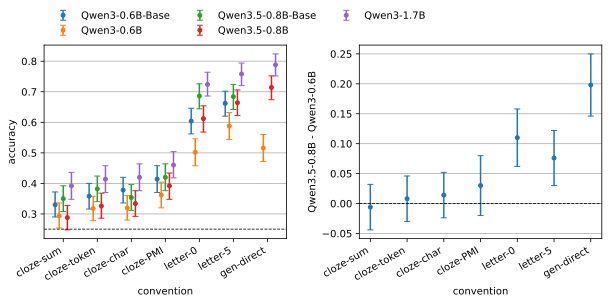

In [50]:
chance = np.mean([1 / len(it[2]) for it in ARC])
_, axes = d2l.plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={
    'wspace': 0.3})
# The conventions run on all 500 items
d2l.plot_intervals(PAIR_CONVS, {m.removeprefix('Qwen/'): tuple(np.array(
    [ACC.get((m, c), (np.nan,) * 3) for c in PAIR_CONVS]).T)
    for m in MODELS}, 'convention', 'accuracy', reference=chance,
    axes=axes[0])
d2l.plot_intervals(PAIR_CONVS, {'Qwen3.5-0.8B - Qwen3-0.6B': tuple(np.array(
    [PAIR_DIFF[c] for c in PAIR_CONVS]).T)}, 'convention',
    'Qwen3.5-0.8B - Qwen3-0.6B', reference=0, axes=axes[1])
axes[0].legend(loc='lower left', bbox_to_anchor=(0, 1), ncol=3,  # above
               frameon=False);  # the panel, clear of every interval

<!-- d2l:prose id=scoring-md-50 fw=all -->

Every interval in this section came from a few lines of bootstrap that treat
the 500 items as independent draws, and the bands of the GSM8K pool
resampled problems and passed over the samples inside them. We judged
differences by whether an interval excludes zero, and twice the verdict was
"not resolved". How many items would it have taken to resolve seven points?
What does a paired test add? Does a benchmark that a model may have seen in
training still measure anything, and what do we do when there is no key to
compare with? that section builds the tools for these
questions.

## Summary

A score is a rule that turns the outputs of a model into a number, and the
rule reaches further than one expects: into the format of the prompt, the
normalization and the token boundary, the windows over a long text, the
parser and the token budget of a generated answer, the precision and the
batch size. One checkpoint was right on between 39% and 79% of the same 500
ARC-Challenge questions depending on the rule, and on 83% of the 100 where
it reasoned first. A parser alone moved a GSM8K accuracy from 6% to 42%.
Parts of the rule can be put on firm ground: the wedge condition says where
sum and mean disagree, bits per byte survives a change of tokenizer, and
pass@k has an unbiased estimator whose uncertainty came mostly from the
choice of problems. For the pair of models that we fixed at the start no
convention reversed the ranking, but the gap between them ran from nothing
under cloze scoring to 20 points when the models wrote their answers. A
comparison therefore means something only under one convention, stated in
full.

## Exercises

1. [code] **Normalization on HellaSwag.** HellaSwag asks for the most
   plausible of four endings of a short scene. Its endings are whole
   sentences of unequal length. The dataset `Rowan/hellaswag` is a set of
   parquet files that `huggingface_hub.hf_hub_download` fetches and
   `pd.read_parquet` reads.
    1. Score 2,000 validation items, chosen by the subset rule of this
       section, with the scene as the prompt and the endings as choices,
       under `'sum'` and `'char'`, for the two base checkpoints. How large
       is the effect of normalization on accuracy, compared with
       ARC-Challenge?
    1. Compute the length spread of the items and the disagreement of the
       two rules by thirds, as in that section. Does
       the equation account for the difference between the two
       benchmarks?

1. [code] **Calibration under each convention.** The registered scores,
   `result('arc-scores')`, suffice for this problem, and it needs no GPU.
    1. For the cloze sum, the rate per character, PMI and letter-0, turn the
       scores of each item into probabilities with a softmax, and compute
       the expected calibration error and a reliability diagram for
       Qwen3-1.7B (that section). Do calibration and
       accuracy rank the four conventions alike?
    1. A softmax of scores per character is a softmax of summed scores at a
       temperature that differs from choice to choice. Write the temperature
       down. What does it do to the confidence on items with long options?
    1. Fit one temperature per convention on half of the items and compute
       the calibration error on the other half. Which convention gains
       most?

1. **Bits per byte by hand.**
    1. A model reaches a perplexity of 16 per token on a text. A second
       tokenizer cuts every token of the first in two, and a second model
       assigns the same probability to every text as the first. What are
       the perplexity per token and the bits per byte of the second model,
       relative to the first?
    1. `bits_per_byte` scores a long text with windows of $w$ tokens and a
       stride of $w/4$. How many positions does the model process per
       scored token, and from how many tokens of context is a token after
       the first window predicted at least?
    1. In that section halving the stride lowered the score by
       0.06 bits per byte for windows of 512 tokens and by 0.02 for windows
       of 2,048. Why is the gain smaller for the longer window?

1. **The plug-in estimate and the variance of pass@k.** For one problem
   with $p = 0.3$ and $k = 5$, that section found a variance of
   0.018 for the estimator $\hat U$ from $n = 20$ samples.
    1. Show that the plug-in estimate $1 - (1 - c/n)^k$ never exceeds
       $\hat U$, with equality only if $k = 1$, $c = 0$ or $c = n$. Hint:
       write $\binom{n-c}{k} / \binom{n}{k}$ as a product of $k$ factors and
       compare each factor with $(n-c)/n$.
    1. For large $n$, $\hat U$ is close to $1 - (1 - c/n)^k$. Expand this
       function of $c/n$ to first order around $p$ and show that the
       variance is approximately $k^2 p (1-p)^{2k-1} / n$. Evaluate the
       approximation at $n = 20$.
    1. Which of the two values at $n = 20$ is larger, and why does their
       difference shrink as $n$ grows?

1. **Samples or problems.** For pass@1 the variance of the mean over $M$
   problems with $n$ samples each is $(w/n + b)/M$, where
   $w = \mathbb{E}[p_i (1 - p_i)]$ is the variance within problems and
   $b = \textrm{Var}[p_i]$ the variance between them.
    1. With a fixed budget of $nM$ samples and as many problems as we like,
       which $n$ minimizes the variance?
    1. Suppose that writing and checking a problem costs as much as $r$
       samples, so that the budget is $M(n + r)$. Find the best $n$ in terms
       of $w$, $b$ and $r$.
    1. Estimate $w$ and $b$ for both models from the output of the variance
       cell in that section, and evaluate the best $n$ for
       $r = 10$ and $r = 1000$. For which uses of a pool is that $n$ too
       small, whatever the variance says?

1. [code] **Minimum Bayes risk.** ●● Majority voting needs an extractor.
   Minimum-Bayes-risk selection does not: it returns the sample that is on
   average most similar to the other samples. The registered pool suffices,
   and the problem needs no GPU.
    1. Implement it for the GSM8K pool, with `d2l.chrf` between whole
       solutions as the similarity (that section), and compare its
       accuracy with maj@8, paired over problems.
    1. Show that majority voting is the same rule with the similarity "1 if
       two samples commit to the same answer, and 0 otherwise".
    1. On which problems do the two rules choose differently, and which of
       them is right more often there?

1. [code] **Batch size and margins.** ● A prediction changes with the batch
   size when a score moves by more than a margin. This problem needs a GPU.
    1. Score the 500 items in the cloze format with Qwen3-0.6B at batch
       sizes 1 and 32, in bf16 and in fp32, and count the predictions that
       change under the cloze sum.
    1. For bf16, plot the distribution of the score changes and that of the
       margins. From the two distributions, predict the number of changed
       predictions under the assumption that the change of an item is
       independent of its margin, and compare with the count.
    1. Is the drift between batch sizes 8 and 32 smaller than between 1 and
       32? What does the answer suggest about its source?

1. [code] **Letter preferences.** ● Without demonstrations Qwen3.5-0.8B
   chose D on 223 of the 500 items. The first two parts need a GPU. The
   third can be done on the registered scores.
    1. Score every four-option item under the four cyclic rotations of its
       options, so that each option stands once behind each letter. How
       often does the prediction follow the option, and how often the
       letter?
    1. Average the log-probability of each option over the four rotations
       and predict from the average. Does the preference for D disappear?
       Compare the accuracy with letter-0 and letter-5, with paired
       intervals.
    1. The rotations take four forward passes per item. Estimate the prior
       over the letters from 50 items instead, subtract its logarithm from
       the letter scores of the others, as the contextual calibration of
       that section does, and compare.

1. [code] **A scoring audit.** ●● The Qwen3 report
   [@Yang.Li.Yang.ea.2025] lists a 5-shot accuracy of 52.81 on the
   MMLU benchmark for Qwen3-0.6B-Base. The dataset `cais/mmlu` is a set of
   parquet files with one folder per subject.
    1. Score 1,000 test questions, chosen by the subset rule of this
       section, with `d2l.format_mc` in the `mmlu` format. Use the five
       development questions of each subject as demonstrations and put the
       line "The following are multiple choice questions (with answers)
       about {subject}." in front. Report the accuracy with a bootstrap
       interval. Does it contain the published number?
    1. Change one part of the convention at a time: no subject line, no
       demonstrations, the cloze format with `'char'`, batch size 1, fp32.
       Tabulate the paired difference from the first part for each change.
    1. Which of these parts would a report have to state for a reader to
       reproduce its number to within one point?

1. [extended] **HumanEval in a container.** ●● In a container without
   network access, draw 10 samples for each of 40 problems of HumanEval
   (dataset `openai/openai_humaneval`) from Qwen3-1.7B, run them with
   `d2l.run_python_tests`, and report pass@1, pass@5 and pass@10 with
   intervals over problems. Compare the unbiased estimates with the plug-in
   ones. What does the container protect against that the limits of
   `run_python_tests` do not?